In [3]:
import sys

print(sys.executable)

/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/bin/python


In [4]:
import pandas as pd

calendar = pd.read_csv("../data/raw/calendar.csv")
calendar.shape
calendar.head()

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [5]:
calendar.info()

<class 'pandas.DataFrame'>
RangeIndex: 1969 entries, 0 to 1968
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   date          1969 non-null   str  
 1   wm_yr_wk      1969 non-null   int64
 2   weekday       1969 non-null   str  
 3   wday          1969 non-null   int64
 4   month         1969 non-null   int64
 5   year          1969 non-null   int64
 6   d             1969 non-null   str  
 7   event_name_1  162 non-null    str  
 8   event_type_1  162 non-null    str  
 9   event_name_2  5 non-null      str  
 10  event_type_2  5 non-null      str  
 11  snap_CA       1969 non-null   int64
 12  snap_TX       1969 non-null   int64
 13  snap_WI       1969 non-null   int64
dtypes: int64(7), str(7)
memory usage: 215.5 KB


In [6]:
sell_prices = pd.read_csv("../data/raw/sell_prices.csv")
sell_prices.shape

(6841121, 4)

In [7]:
sell_prices.head()

,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


In [8]:
sell_prices.info()

<class 'pandas.DataFrame'>
RangeIndex: 6841121 entries, 0 to 6841120
Data columns (total 4 columns):
 #   Column      Dtype  
---  ------      -----  
 0   store_id    str    
 1   item_id     str    
 2   wm_yr_wk    int64  
 3   sell_price  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 208.8 MB


In [9]:
print("Stores:", sell_prices["store_id"].nunique())
print("Items:", sell_prices["item_id"].nunique())
print("Weeks:", sell_prices["wm_yr_wk"].nunique())

print("\nMissing values:")
print(sell_prices.isnull().sum())

print("\nDuplicate rows:", sell_prices.duplicated().sum())

Stores: 10
Items: 3049
Weeks: 282

Missing values:
store_id      0
item_id       0
wm_yr_wk      0
sell_price    0
dtype: int64

Duplicate rows: 0


In [10]:
sell_prices["store_id"] = sell_prices["store_id"].astype("category")
sell_prices["item_id"] = sell_prices["item_id"].astype("category")

sell_prices["wm_yr_wk"] = pd.to_numeric(
    sell_prices["wm_yr_wk"],
    downcast="integer"
)

sell_prices["sell_price"] = pd.to_numeric(
    sell_prices["sell_price"],
    downcast="float"
)

In [11]:
sell_prices.info()

<class 'pandas.DataFrame'>
RangeIndex: 6841121 entries, 0 to 6841120
Data columns (total 4 columns):
 #   Column      Dtype   
---  ------      -----   
 0   store_id    category
 1   item_id     category
 2   wm_yr_wk    int16   
 3   sell_price  float32 
dtypes: category(2), float32(1), int16(1)
memory usage: 58.7 MB


In [12]:
sell_prices["sell_price"].describe()

count    6.841121e+06
mean     4.410953e+00
std      3.408814e+00
min      1.000000e-02
25%      2.180000e+00
50%      3.470000e+00
75%      5.840000e+00
max      1.073200e+02
Name: sell_price, dtype: float64

In [13]:
sales = pd.read_csv("../data/raw/sales_train_evaluation.csv")

sales.shape

(30490, 1947)

In [14]:
sales.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1932,d_1933,d_1934,d_1935,d_1936,d_1937,d_1938,d_1939,d_1940,d_1941
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,4,0,0,0,0,3,3,0,1
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,1,2,1,1,0,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,2,0,0,0,2,3,0,1
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,1,0,4,0,1,3,0,2,6
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,2,1,0,0,2,1,0


In [15]:
sales.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 30490 entries, 0 to 30489
Columns: 1947 entries, id to d_1941
dtypes: int64(1941), str(6)
memory usage: 461.9 MB


In [16]:
day_cols = [col for col in sales.columns if col.startswith("d_")]

sales[day_cols].max().max()

np.int64(763)

In [17]:
sales[day_cols] = sales[day_cols].astype("int16")

In [18]:
id_cols = ["item_id", "dept_id", "cat_id", "store_id", "state_id"]

for col in id_cols:
    sales[col] = sales[col].astype("category")

In [19]:
sales.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 30490 entries, 0 to 30489
Columns: 1947 entries, id to d_1941
dtypes: category(5), int16(1941), str(1)
memory usage: 115.5 MB


In [20]:
print("Categories:", sales["cat_id"].nunique())
print("Departments:", sales["dept_id"].nunique())
print("States:", sales["state_id"].nunique())
print("Stores:", sales["store_id"].nunique())

print("\nCategories:")
print(sales["cat_id"].value_counts())

print("\nDepartments:")
print(sales["dept_id"].value_counts())

print("\nStores:")
print(sales["store_id"].value_counts())

Categories: 3
Departments: 7
States: 3
Stores: 10

Categories:
cat_id
FOODS        14370
HOUSEHOLD    10470
HOBBIES       5650
Name: count, dtype: int64

Departments:
dept_id
FOODS_3        8230
HOUSEHOLD_1    5320
HOUSEHOLD_2    5150
HOBBIES_1      4160
FOODS_2        3980
FOODS_1        2160
HOBBIES_2      1490
Name: count, dtype: int64

Stores:
store_id
CA_1    3049
CA_2    3049
CA_3    3049
CA_4    3049
TX_1    3049
TX_2    3049
TX_3    3049
WI_1    3049
WI_2    3049
WI_3    3049
Name: count, dtype: int64


In [21]:
sales["total_sales"] = sales[day_cols].sum(axis=1)

/tmp/ipykernel_9192/3239839139.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sales["total_sales"] = sales[day_cols].sum(axis=1)


In [22]:
category_sales = (
    sales.groupby("cat_id", observed=True)["total_sales"]
    .sum()
    .sort_values(ascending=False)
)

category_sales

cat_id
FOODS        45922427
HOUSEHOLD    14764090
HOBBIES       6240656
Name: total_sales, dtype: int64

In [23]:
store_sales = (
    sales.groupby("store_id", observed=True)["total_sales"]
    .sum()
    .sort_values(ascending=False)
)

store_sales

store_id
CA_3    11363540
CA_1     7832248
TX_2     7329642
WI_2     6697988
WI_3     6542557
TX_3     6205940
CA_2     5818395
TX_1     5692823
WI_1     5261506
CA_4     4182534
Name: total_sales, dtype: int64

In [24]:
department_sales = (
    sales.groupby("dept_id", observed=True)["total_sales"]
    .sum()
    .sort_values(ascending=False)
)

department_sales

dept_id
FOODS_3        32937002
HOUSEHOLD_1    11722853
FOODS_2         7795025
HOBBIES_1       5699014
FOODS_1         5190400
HOUSEHOLD_2     3041237
HOBBIES_2        541642
Name: total_sales, dtype: int64

In [28]:
import matplotlib.pyplot as plt

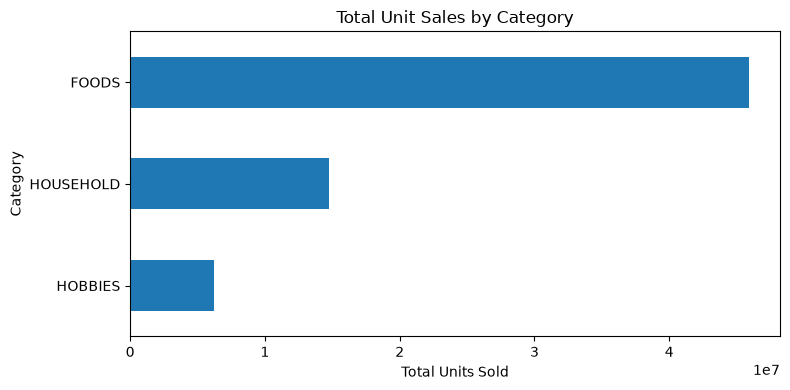

In [29]:
import matplotlib.pyplot as plt

category_sales.sort_values().plot(
    kind="barh",
    figsize=(8, 4)
)

plt.title("Total Unit Sales by Category")
plt.xlabel("Total Units Sold")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

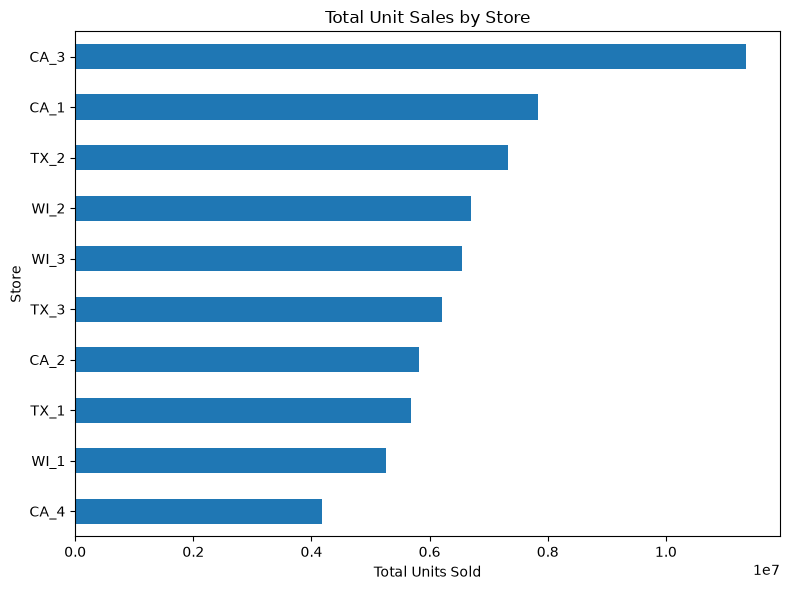

In [30]:
store_sales.sort_values().plot(
    kind="barh",
    figsize=(8, 6)
)

plt.title("Total Unit Sales by Store")
plt.xlabel("Total Units Sold")
plt.ylabel("Store")
plt.tight_layout()
plt.show()

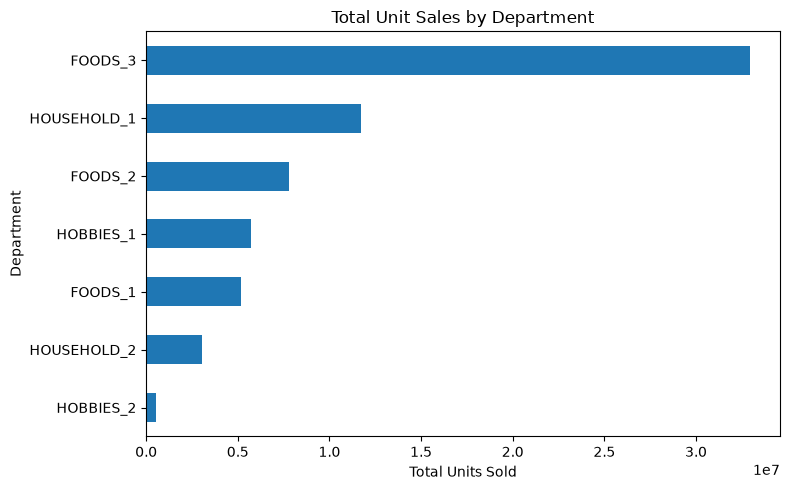

In [31]:
department_sales.sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Total Unit Sales by Department")
plt.xlabel("Total Units Sold")
plt.ylabel("Department")
plt.tight_layout()
plt.show()

In [32]:
calendar["date"] = pd.to_datetime(calendar["date"])

calendar[["date", "d", "wm_yr_wk"]].head()

,date,d,wm_yr_wk
0,2011-01-29,d_1,11101
1,2011-01-30,d_2,11101
2,2011-01-31,d_3,11101
3,2011-02-01,d_4,11101
4,2011-02-02,d_5,11101


In [33]:
day_cols[:5]

['d_1', 'd_2', 'd_3', 'd_4', 'd_5']

In [34]:
daily_sales = sales[day_cols].sum(axis=0).reset_index()

daily_sales.columns = ["d", "total_sales"]

daily_sales.head()

,d,total_sales
0,d_1,32631
1,d_2,31749
2,d_3,23783
3,d_4,25412
4,d_5,19146


In [35]:
daily_sales = daily_sales.merge(
    calendar[["d", "date", "weekday", "wday", "month", "year"]],
    on="d",
    how="left"
)

daily_sales.head()

,d,total_sales,date,weekday,wday,month,year
0,d_1,32631,2011-01-29,Saturday,1,1,2011
1,d_2,31749,2011-01-30,Sunday,2,1,2011
2,d_3,23783,2011-01-31,Monday,3,1,2011
3,d_4,25412,2011-02-01,Tuesday,4,2,2011
4,d_5,19146,2011-02-02,Wednesday,5,2,2011


In [36]:
daily_sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 1941 entries, 0 to 1940
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   d            1941 non-null   str           
 1   total_sales  1941 non-null   int64         
 2   date         1941 non-null   datetime64[us]
 3   weekday      1941 non-null   str           
 4   wday         1941 non-null   int64         
 5   month        1941 non-null   int64         
 6   year         1941 non-null   int64         
dtypes: datetime64[us](1), int64(4), str(2)
memory usage: 106.3 KB


In [37]:
daily_sales[["date", "total_sales"]].head()

,date,total_sales
0,2011-01-29,32631
1,2011-01-30,31749
2,2011-01-31,23783
3,2011-02-01,25412
4,2011-02-02,19146


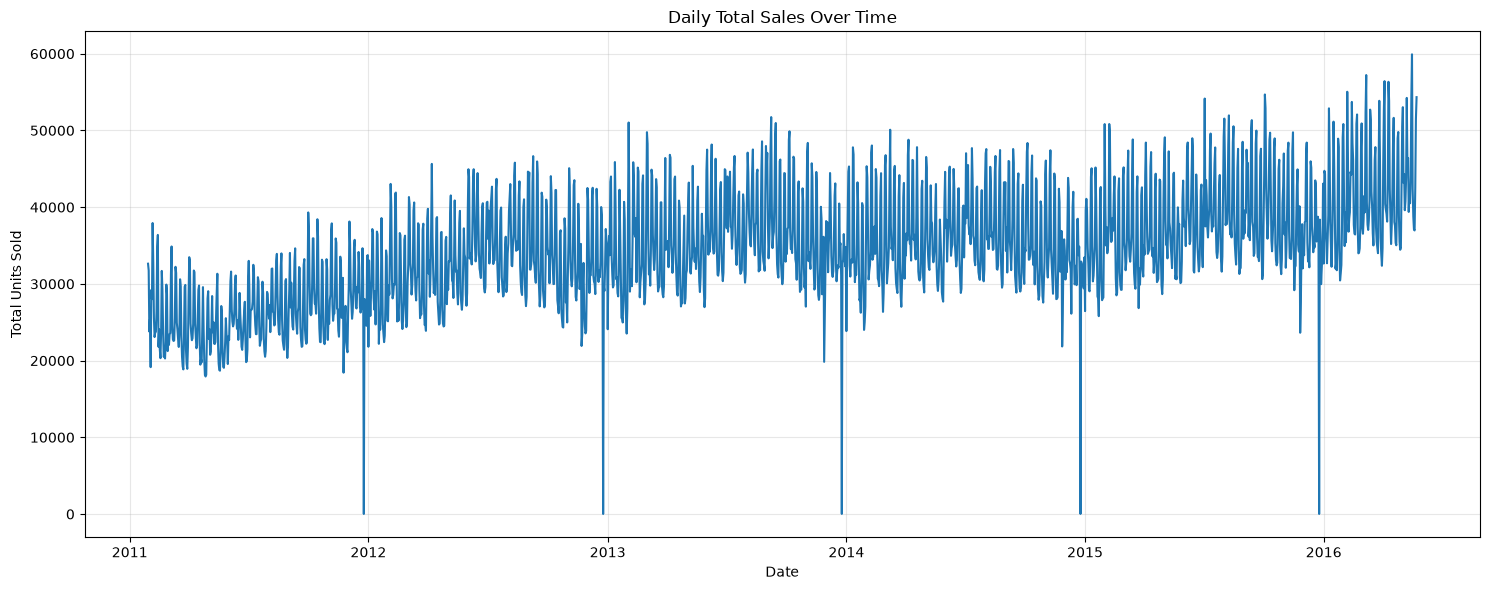

In [38]:
plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales["date"],
    daily_sales["total_sales"]
)

plt.title("Daily Total Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [39]:
daily_sales.nsmallest(10, "total_sales")[
    ["date", "weekday", "total_sales"]
]

,date,weekday,total_sales
696,2012-12-25,Tuesday,11
330,2011-12-25,Sunday,13
1791,2015-12-25,Friday,14
1061,2013-12-25,Wednesday,20
1426,2014-12-25,Thursday,20
88,2011-04-27,Wednesday,17929
87,2011-04-26,Tuesday,18113
89,2011-04-28,Thursday,18145
299,2011-11-24,Thursday,18427
110,2011-05-19,Thursday,18684


In [40]:
calendar[
    calendar["date"].dt.strftime("%m-%d") == "12-25"
][
    ["date", "weekday", "event_name_1", "event_type_1"]
]

,date,weekday,event_name_1,event_type_1
330,2011-12-25,Sunday,Christmas,National
696,2012-12-25,Tuesday,Christmas,National
1061,2013-12-25,Wednesday,Christmas,National
1426,2014-12-25,Thursday,Christmas,National
1791,2015-12-25,Friday,Christmas,National


In [41]:
daily_sales["rolling_7"] = (
    daily_sales["total_sales"]
    .rolling(window=7)
    .mean()
)

daily_sales["rolling_28"] = (
    daily_sales["total_sales"]
    .rolling(window=28)
    .mean()
)

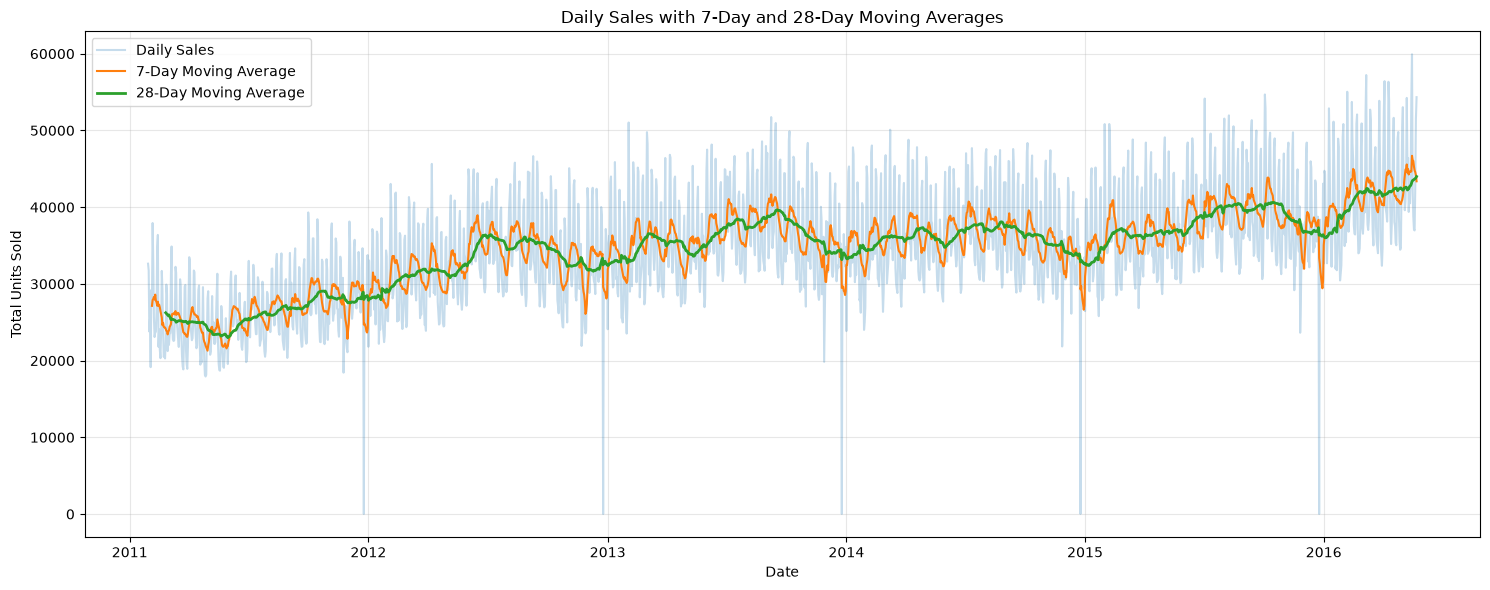

In [42]:
plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales["date"],
    daily_sales["total_sales"],
    alpha=0.25,
    label="Daily Sales"
)

plt.plot(
    daily_sales["date"],
    daily_sales["rolling_7"],
    label="7-Day Moving Average"
)

plt.plot(
    daily_sales["date"],
    daily_sales["rolling_28"],
    linewidth=2,
    label="28-Day Moving Average"
)

plt.title("Daily Sales with 7-Day and 28-Day Moving Averages")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [43]:
weekday_sales = (
    daily_sales.groupby("weekday")["total_sales"]
    .agg(["mean", "median"])
)

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_sales = weekday_sales.reindex(weekday_order)

weekday_sales.round(2)

,mean,median
weekday,,
Monday,32994.93,33451.0
Tuesday,30500.48,30901.0
Wednesday,30130.42,31018.0
Thursday,30321.04,30757.0
Friday,34357.47,34864.0
Saturday,41706.27,42488.0
Sunday,41304.05,42647.5


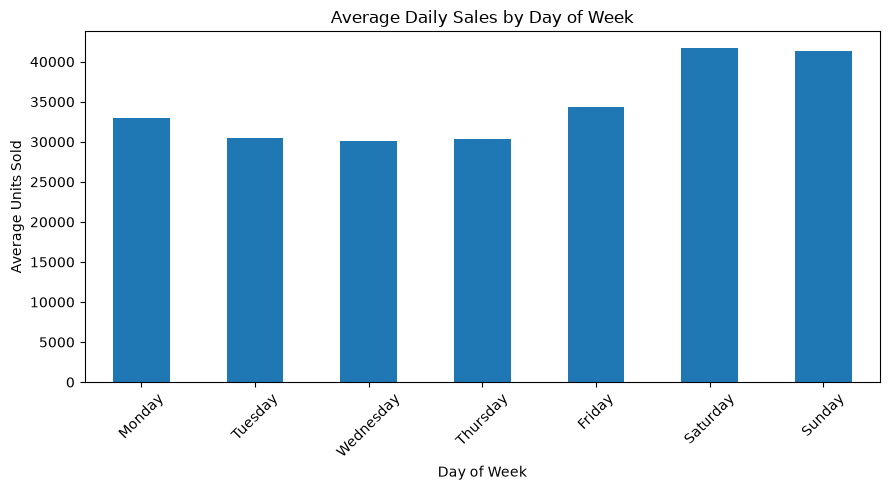

In [44]:
weekday_sales["mean"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Average Daily Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [45]:
daily_sales = daily_sales.merge(
    calendar[
        ["d", "event_name_1", "event_type_1",
         "event_name_2", "event_type_2",
         "snap_CA", "snap_TX", "snap_WI"]
    ],
    on="d",
    how="left"
)

In [46]:
daily_sales = daily_sales.merge(
    calendar[
        ["d", "event_name_1", "event_type_1",
         "event_name_2", "event_type_2",
         "snap_CA", "snap_TX", "snap_WI"]
    ],
    on="d",
    how="left"
)
daily_sales.head()

,d,total_sales,date,weekday,wday,month,year,rolling_7,rolling_28,event_name_1_x,...,snap_CA_x,snap_TX_x,snap_WI_x,event_name_1_y,event_type_1_y,event_name_2_y,event_type_2_y,snap_CA_y,snap_TX_y,snap_WI_y
0,d_1,32631,2011-01-29,Saturday,1,1,2011,NaN,NaN,NaN,...,0,0,0,NaN,NaN,NaN,NaN,0,0,0
1,d_2,31749,2011-01-30,Sunday,2,1,2011,NaN,NaN,NaN,...,0,0,0,NaN,NaN,NaN,NaN,0,0,0
2,d_3,23783,2011-01-31,Monday,3,1,2011,NaN,NaN,NaN,...,0,0,0,NaN,NaN,NaN,NaN,0,0,0
3,d_4,25412,2011-02-01,Tuesday,4,2,2011,NaN,NaN,NaN,...,1,1,0,NaN,NaN,NaN,NaN,1,1,0
4,d_5,19146,2011-02-02,Wednesday,5,2,2011,NaN,NaN,NaN,...,1,0,1,NaN,NaN,NaN,NaN,1,0,1


In [47]:
daily_sales["event_type"] = (
    daily_sales["event_type_1_y"]
    .fillna("No Event")
)

daily_sales["event_type"].value_counts()

event_type
No Event     1783
Religious      54
National       51
Cultural       37
Sporting       16
Name: count, dtype: int64

In [48]:
daily_sales["event_type_2_y"].value_counts(dropna=False)

event_type_2_y
NaN          1937
Cultural        3
Religious       1
Name: count, dtype: int64

In [49]:
daily_sales["event_type_2_y"].value_counts(dropna=False)

event_type_2_y
NaN          1937
Cultural        3
Religious       1
Name: count, dtype: int64

In [50]:
[col for col in daily_sales.columns if "event" in col]

['event_name_1_x',
 'event_type_1_x',
 'event_name_2_x',
 'event_type_2_x',
 'event_name_1_y',
 'event_type_1_y',
 'event_name_2_y',
 'event_type_2_y',
 'event_type']

In [51]:
event_cols = [col for col in daily_sales.columns if "event_" in col]

daily_sales = daily_sales.drop(columns=event_cols)

In [52]:
[col for col in daily_sales.columns if "event" in col]

[]

In [53]:
daily_sales = daily_sales.merge(
    calendar[
        [
            "d",
            "event_name_1",
            "event_type_1",
            "event_name_2",
            "event_type_2"
        ]
    ],
    on="d",
    how="left"
)

In [54]:
[col for col in daily_sales.columns if "event" in col]

['event_name_1', 'event_type_1', 'event_name_2', 'event_type_2']

In [55]:
daily_sales["event_type"] = (
    daily_sales["event_type_1"]
    .fillna(daily_sales["event_type_2"])
    .fillna("No Event")
)

In [56]:
daily_sales["event_type"].value_counts()

event_type
No Event     1783
Religious      54
National       51
Cultural       37
Sporting       16
Name: count, dtype: int64

In [57]:
event_sales_summary = (
    daily_sales
    .groupby("event_type")["total_sales"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

event_sales_summary.round(2)

,count,mean,median
event_type,,,
Sporting,16,35796.06,34998.0
Cultural,37,34718.59,35820.0
No Event,1783,34609.34,33817.0
Religious,54,34426.24,34214.0
National,51,29458.51,32656.0


In [58]:
no_event_mean = event_sales_summary.loc["No Event", "mean"]

event_sales_summary["difference_vs_no_event_%"] = (
    (event_sales_summary["mean"] - no_event_mean)
    / no_event_mean * 100
)

event_sales_summary.round(2)

,count,mean,median,difference_vs_no_event_%
event_type,,,,
Sporting,16,35796.06,34998.0,3.43
Cultural,37,34718.59,35820.0,0.32
No Event,1783,34609.34,33817.0,0.00
Religious,54,34426.24,34214.0,-0.53
National,51,29458.51,32656.0,-14.88


In [59]:
event_sales_summary = (
    daily_sales
    .groupby("event_type")["total_sales"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

event_sales_summary.round(2)

,count,mean,median
event_type,,,
Sporting,16,35796.06,34998.0
Cultural,37,34718.59,35820.0
No Event,1783,34609.34,33817.0
Religious,54,34426.24,34214.0
National,51,29458.51,32656.0


In [60]:
no_event_mean = event_sales_summary.loc["No Event", "mean"]

event_sales_summary["difference_vs_no_event_%"] = (
    (event_sales_summary["mean"] - no_event_mean)
    / no_event_mean * 100
)

event_sales_summary.round(2)

,count,mean,median,difference_vs_no_event_%
event_type,,,,
Sporting,16,35796.06,34998.0,3.43
Cultural,37,34718.59,35820.0,0.32
No Event,1783,34609.34,33817.0,0.00
Religious,54,34426.24,34214.0,-0.53
National,51,29458.51,32656.0,-14.88


In [61]:
state_daily_sales = {}

for state in ["CA", "TX", "WI"]:
    state_mask = sales["state_id"] == state

    state_daily_sales[state] = (
        sales.loc[state_mask, day_cols]
        .sum(axis=0)
    )

state_daily_sales["CA"].head()

d_1    14195
d_2    13805
d_3    10108
d_4    11047
d_5     9925
dtype: int64

In [62]:
state_daily_sales = {}

for state in ["CA", "TX", "WI"]:
    state_mask = sales["state_id"] == state

    state_daily_sales[state] = (
        sales.loc[state_mask, day_cols]
        .sum(axis=0)
    )

state_daily_sales["TX"].head()

d_1    9438
d_2    9630
d_3    6778
d_4    7381
d_5    5912
dtype: int64

In [63]:
state_sales_df = pd.DataFrame({
    "d": day_cols,
    "CA_sales": state_daily_sales["CA"].values,
    "TX_sales": state_daily_sales["TX"].values,
    "WI_sales": state_daily_sales["WI"].values
})

state_sales_df.head()

,d,CA_sales,TX_sales,WI_sales
0,d_1,14195,9438,8998
1,d_2,13805,9630,8314
2,d_3,10108,6778,6897
3,d_4,11047,7381,6984
4,d_5,9925,5912,3309


In [64]:
state_sales_df = state_sales_df.merge(
    calendar[
        ["d", "date", "snap_CA", "snap_TX", "snap_WI"]
    ],
    on="d",
    how="left"
)

state_sales_df.head()

,d,CA_sales,TX_sales,WI_sales,date,snap_CA,snap_TX,snap_WI
0,d_1,14195,9438,8998,2011-01-29,0,0,0
1,d_2,13805,9630,8314,2011-01-30,0,0,0
2,d_3,10108,6778,6897,2011-01-31,0,0,0
3,d_4,11047,7381,6984,2011-02-01,1,1,0
4,d_5,9925,5912,3309,2011-02-02,1,0,1


In [65]:
snap_results = []

for state in ["CA", "TX", "WI"]:
    result = (
        state_sales_df
        .groupby(f"snap_{state}")[f"{state}_sales"]
        .agg(["count", "mean", "median"])
    )

    no_snap_mean = result.loc[0, "mean"]
    snap_mean = result.loc[1, "mean"]

    difference_pct = (
        (snap_mean - no_snap_mean)
        / no_snap_mean * 100
    )

    snap_results.append({
        "state": state,
        "no_snap_mean": no_snap_mean,
        "snap_mean": snap_mean,
        "difference_pct": difference_pct
    })

snap_summary = pd.DataFrame(snap_results)

snap_summary.round(2)

,state,no_snap_mean,snap_mean,difference_pct
0,CA,14657.74,15823.42,7.95
1,TX,9543.86,10643.51,11.52
2,WI,8892.50,10832.66,21.82


In [66]:
price_variation = (
    sell_prices
    .groupby(["store_id", "item_id"], observed=True)["sell_price"]
    .nunique()
)

price_variation.describe()

count    30490.000000
mean         2.769367
std          1.893627
min          1.000000
25%          1.000000
50%          2.000000
75%          4.000000
max         21.000000
Name: sell_price, dtype: float64

In [67]:
changed_price_pct = (
    (price_variation > 1).mean() * 100
)

print(f"Price changed: {changed_price_pct:.2f}%")

Price changed: 72.95%


In [68]:
price_variation.value_counts().sort_index().head(15)

sell_price
1     8247
2     8396
3     6104
4     3575
5     1804
6     1006
7      534
8      368
9      140
10      84
11      76
12      63
13      42
14      15
15       8
Name: count, dtype: int64

In [69]:
sell_prices = sell_prices.sort_values(
    ["store_id", "item_id", "wm_yr_wk"]
).copy()

In [70]:
sell_prices["previous_price"] = (
    sell_prices
    .groupby(["store_id", "item_id"], observed=True)["sell_price"]
    .shift(1)
)

In [71]:
sell_prices["price_change"] = (
    sell_prices["sell_price"]
    - sell_prices["previous_price"]
)

In [72]:
sell_prices["price_change_pct"] = (
    sell_prices["price_change"]
    / sell_prices["previous_price"] * 100
)

In [73]:
price_change_counts = pd.Series({
    "Price Decreased": (sell_prices["price_change"] < 0).sum(),
    "No Change": (sell_prices["price_change"] == 0).sum(),
    "Price Increased": (sell_prices["price_change"] > 0).sum()
})

price_change_counts

Price Decreased      33603
No Change          6731816
Price Increased      45212
dtype: int64

In [74]:
sell_prices["price_change_pct"].describe()

count    6.810631e+06
mean     1.244816e-01
std      4.507183e+01
min     -9.988864e+01
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      8.969999e+04
Name: price_change_pct, dtype: float64

In [75]:
sell_prices.nlargest(10, "price_change_pct")[
    [
        "store_id",
        "item_id",
        "wm_yr_wk",
        "previous_price",
        "sell_price",
        "price_change",
        "price_change_pct"
    ]
]

,store_id,item_id,wm_yr_wk,previous_price,sell_price,price_change,price_change_pct
4877377,WI_1,HOBBIES_1_338,11344,0.01,8.98,8.969999,89699.992188
5044268,WI_1,HOUSEHOLD_1_533,11409,0.01,4.97,4.960000,49599.996094
6282350,WI_3,HOUSEHOLD_1_036,11445,0.01,2.98,2.970000,29700.000000
5316538,WI_1,FOODS_3_122,11426,0.01,2.50,2.490000,24900.000000
225728,CA_1,HOUSEHOLD_1_443,11443,0.01,2.47,2.460000,24600.001953
6015653,WI_2,FOODS_3_242,11539,0.05,9.86,9.809999,19619.998047
6433466,WI_3,HOUSEHOLD_2_182,11609,0.05,6.98,6.930000,13859.999023
4708580,TX_3,FOODS_3_410,11335,0.02,2.68,2.660000,13300.000000
2617307,CA_4,FOODS_3_413,11149,0.01,1.00,0.990000,9900.000000
5590555,WI_2,HOBBIES_2_128,11327,0.07,4.97,4.900000,6999.999023


In [76]:
sell_prices.nsmallest(10, "price_change_pct")[
    [
        "store_id",
        "item_id",
        "wm_yr_wk",
        "previous_price",
        "sell_price",
        "price_change",
        "price_change_pct"
    ]
]

,store_id,item_id,wm_yr_wk,previous_price,sell_price,price_change,price_change_pct
4877375,WI_1,HOBBIES_1_338,11342,8.98,0.01,-8.969999,-99.888641
5044267,WI_1,HOUSEHOLD_1_533,11408,4.97,0.01,-4.960000,-99.798790
6282347,WI_3,HOUSEHOLD_1_036,11442,2.98,0.01,-2.970000,-99.664429
5316537,WI_1,FOODS_3_122,11425,2.50,0.01,-2.490000,-99.599998
225727,CA_1,HOUSEHOLD_1_443,11442,2.47,0.01,-2.460000,-99.595139
6015652,WI_2,FOODS_3_242,11538,9.86,0.05,-9.809999,-99.492905
6433465,WI_3,HOUSEHOLD_2_182,11608,6.98,0.05,-6.930000,-99.283669
4708579,TX_3,FOODS_3_410,11334,2.68,0.02,-2.660000,-99.253731
2617306,CA_4,FOODS_3_413,11148,1.00,0.01,-0.990000,-99.000000
113263,CA_1,HOBBIES_2_075,11508,2.88,0.05,-2.830000,-98.263893


In [77]:
sell_prices["price_direction"] = "No Change"

sell_prices.loc[
    sell_prices["price_change"] > 0,
    "price_direction"
] = "Increase"

sell_prices.loc[
    sell_prices["price_change"] < 0,
    "price_direction"
] = "Decrease"

In [78]:
sell_prices["price_direction"].value_counts()

price_direction
No Change    6762306
Increase       45212
Decrease       33603
Name: count, dtype: int64

In [79]:
extreme_low_prices = sell_prices[
    sell_prices["sell_price"] <= 0.10
]

print("Records with price <= $0.10:", len(extreme_low_prices))
print(
    "Unique item-store combinations:",
    extreme_low_prices[["store_id", "item_id"]]
    .drop_duplicates()
    .shape[0]
)

Records with price <= $0.10: 331
Unique item-store combinations: 57


In [80]:
print(
    f"Share of price records <= $0.10: "
    f"{len(extreme_low_prices) / len(sell_prices) * 100:.4f}%"
)

Share of price records <= $0.10: 0.0048%


In [81]:
day_week_map = calendar[
    calendar["d"].isin(day_cols)
][["d", "wm_yr_wk"]]

day_week_map.head(10)

,d,wm_yr_wk
0,d_1,11101
1,d_2,11101
2,d_3,11101
3,d_4,11101
4,d_5,11101
5,d_6,11101
6,d_7,11101
7,d_8,11102
8,d_9,11102
9,d_10,11102


In [82]:
day_week_map.groupby("wm_yr_wk").size().value_counts().sort_index()

2      1
7    277
Name: count, dtype: int64

In [110]:
weekly_sales_list = []

for week in weeks:
    week_days = day_week_map.loc[
        day_week_map["wm_yr_wk"] == week,
        "d"
    ].tolist()

    week_sales = sales[week_days].sum(axis=1)

    temp = pd.DataFrame({
        "store_id": sales["store_id"],
        "item_id": sales["item_id"],
        "wm_yr_wk": week,
        "weekly_sales": week_sales
    })

    weekly_sales_list.append(temp)

In [ ]:
weeks = day_week_map["wm_yr_wk"].unique()

weekly_sales_list = []

for week in weeks:
    week_days = day_week_map.loc[
        day_week_map["wm_yr_wk"] == week,
        "d"
    ].tolist()

    week_sales = sales[week_days].sum(axis=1)

    temp = pd.DataFrame({
        "store_id": sales["store_id"],
        "item_id": sales["item_id"],
        "wm_yr_wk": week,
        "weekly_sales": week_sales
    })

    weekly_sales_list.append(temp)

In [112]:
len (weeks)

278

In [113]:
weekly_sales = pd.concat(
    weekly_sales_list,
    ignore_index=True
)

weekly_sales.shape

(8476220, 4)

In [114]:
weekly_sales.head()

,store_id,item_id,wm_yr_wk,weekly_sales
0,CA_1,HOBBIES_1_001,11101,0
1,CA_1,HOBBIES_1_002,11101,0
2,CA_1,HOBBIES_1_003,11101,0
3,CA_1,HOBBIES_1_004,11101,0
4,CA_1,HOBBIES_1_005,11101,0


In [115]:
weekly_sales.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 8476220 entries, 0 to 8476219
Data columns (total 4 columns):
 #   Column        Dtype   
---  ------        -----   
 0   store_id      category
 1   item_id       category
 2   wm_yr_wk      int64   
 3   weekly_sales  int64   
dtypes: category(2), int64(2)
memory usage: 153.8 MB


In [116]:
weekly_sales["weekly_sales"].max()

np.int64(3539)

In [117]:
weekly_sales["wm_yr_wk"] = weekly_sales["wm_yr_wk"].astype("int16")
weekly_sales["weekly_sales"] = weekly_sales["weekly_sales"].astype("int16")

In [118]:
weekly_sales.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 8476220 entries, 0 to 8476219
Data columns (total 4 columns):
 #   Column        Dtype   
---  ------        -----   
 0   store_id      category
 1   item_id       category
 2   wm_yr_wk      int16   
 3   weekly_sales  int16   
dtypes: category(2), int16(2)
memory usage: 56.8 MB


In [119]:
print(weekly_sales[["store_id", "item_id", "wm_yr_wk"]].dtypes)
print()
print(sell_prices[["store_id", "item_id", "wm_yr_wk"]].dtypes)

store_id    category
item_id     category
wm_yr_wk       int16
dtype: object

store_id    category
item_id     category
wm_yr_wk       int16
dtype: object


In [132]:
weekly_price_sales = weekly_sales.merge(
    sell_prices[
        [
            "store_id",
            "item_id",
            "wm_yr_wk",
            "sell_price",
            "previous_price",
            "price_change",
            "price_change_pct",
            "price_direction"
        ]
    ],
    on=["store_id", "item_id", "wm_yr_wk"],
    how="left"
)

In [133]:
print("Shape:", weekly_price_sales.shape)

print(
    "Missing price:",
    weekly_price_sales["sell_price"].isna().sum()
)

weekly_price_sales.head()

Shape: (8476220, 9)
Missing price: 1757059


,store_id,item_id,wm_yr_wk,weekly_sales,sell_price,previous_price,price_change,price_change_pct,price_direction
0,CA_1,HOBBIES_1_001,11101,0,NaN,NaN,NaN,NaN,NaN
1,CA_1,HOBBIES_1_002,11101,0,NaN,NaN,NaN,NaN,NaN
2,CA_1,HOBBIES_1_003,11101,0,NaN,NaN,NaN,NaN,NaN
3,CA_1,HOBBIES_1_004,11101,0,NaN,NaN,NaN,NaN,NaN
4,CA_1,HOBBIES_1_005,11101,0,NaN,NaN,NaN,NaN,NaN


In [134]:
missing_price = weekly_price_sales[
    weekly_price_sales["sell_price"].isna()
]

missing_price["weekly_sales"].describe()

count    1757059.0
mean           0.0
std            0.0
min            0.0
25%            0.0
50%            0.0
75%            0.0
max            0.0
Name: weekly_sales, dtype: float64

In [135]:
print(
    "Missing price & zero sales:",
    ((weekly_price_sales["sell_price"].isna()) &
     (weekly_price_sales["weekly_sales"] == 0)).sum()
)

print(
    "Missing price & positive sales:",
    ((weekly_price_sales["sell_price"].isna()) &
     (weekly_price_sales["weekly_sales"] > 0)).sum()
)

Missing price & zero sales: 1757059
Missing price & positive sales: 0


In [136]:
price_sales_active = weekly_price_sales[
    weekly_price_sales["sell_price"].notna()
].copy()

price_sales_active.shape

(6719161, 9)

In [137]:
price_sales_active = price_sales_active.sort_values(
    ["store_id", "item_id", "wm_yr_wk"]
)

price_sales_active["previous_week_sales"] = (
    price_sales_active
    .groupby(["store_id", "item_id"], observed=True)["weekly_sales"]
    .shift(1)
)

price_sales_active["sales_change"] = (
    price_sales_active["weekly_sales"]
    - price_sales_active["previous_week_sales"]
)

In [138]:
price_demand_summary = (
    price_sales_active
    .groupby("price_direction", observed=True)
    .agg(
        weeks=("weekly_sales", "count"),
        avg_sales=("weekly_sales", "mean"),
        avg_previous_sales=("previous_week_sales", "mean"),
        avg_sales_change=("sales_change", "mean"),
        median_sales_change=("sales_change", "median")
    )
)

price_demand_summary.round(2)

,weeks,avg_sales,avg_previous_sales,avg_sales_change,median_sales_change
price_direction,,,,,
Decrease,33361,11.08,8.81,2.27,1.0
Increase,44696,12.86,11.09,1.77,1.0
No Change,6641104,9.94,9.99,-0.05,0.0


In [139]:
price_sales_active.columns.tolist()

['store_id',
 'item_id',
 'wm_yr_wk',
 'weekly_sales',
 'sell_price',
 'previous_price',
 'price_change',
 'price_change_pct',
 'price_direction',
 'previous_week_sales',
 'sales_change']

In [140]:
week_order = (
    calendar[["wm_yr_wk"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

week_order["week_index"] = range(len(week_order))

week_order.head()

,wm_yr_wk,week_index
0,11101,0
1,11102,1
2,11103,2
3,11104,3
4,11105,4


In [141]:
price_sales_active = price_sales_active.merge(
    week_order,
    on="wm_yr_wk",
    how="left"
)

price_sales_active = price_sales_active.sort_values(
    ["store_id", "item_id", "week_index"]
)

price_sales_active["previous_week_index"] = (
    price_sales_active
    .groupby(["store_id", "item_id"], observed=True)["week_index"]
    .shift(1)
)

price_sales_active["week_gap"] = (
    price_sales_active["week_index"]
    - price_sales_active["previous_week_index"]
)

In [142]:
price_sales_active["week_gap"].value_counts().head(10)

week_gap
1.0    6688671
Name: count, dtype: int64

In [160]:
# Her ürün-mağaza kombinasyonu için normal/ortalama fiyat
weekly_sales["avg_price_item_store"] = (
    weekly_sales
    .groupby(["item_id", "store_id"])["sell_price"]
    .transform("median")
)

# O haftaki fiyatın normal fiyata göre değişimi
weekly_sales["price_ratio"] = (
    weekly_sales["sell_price"] /
    weekly_sales["avg_price_item_store"]
)

weekly_sales[
    ["item_id", "store_id", "sell_price",
     "avg_price_item_store", "price_ratio", "weekly_sales"]
].head()

KeyError: 'Column not found: sell_price'

In [144]:
weekly_price_sales.columns.tolist()

['store_id',
 'item_id',
 'wm_yr_wk',
 'weekly_sales',
 'sell_price',
 'previous_price',
 'price_change',
 'price_change_pct',
 'price_direction']

In [145]:
weekly_sales.columns.tolist()

['store_id', 'item_id', 'wm_yr_wk', 'weekly_sales']

In [146]:
weekly_sales.head()

,store_id,item_id,wm_yr_wk,weekly_sales
0,CA_1,HOBBIES_1_001,11101,0
1,CA_1,HOBBIES_1_002,11101,0
2,CA_1,HOBBIES_1_003,11101,0
3,CA_1,HOBBIES_1_004,11101,0
4,CA_1,HOBBIES_1_005,11101,0


In [147]:
get_ipython().run_line_magic('whos', 'DataFrame')

Variable               Type         Data/Info
---------------------------------------------
calendar               DataFrame    Shape: (1969, 14)
daily_sales            DataFrame    Shape: (1941, 20)
day_week_map           DataFrame    Shape: (1941, 2)
event_sales_summary    DataFrame    Shape: (5, 4)
extreme_low_prices     DataFrame    Shape: (331, 8)
missing_price          DataFrame    Shape: (1757059, 9)
price_demand_summary   DataFrame    Shape: (3, 5)
price_sales_active     DataFrame    Shape: (6719161, 14)
result                 DataFrame    Shape: (2, 3)
sales                  DataFrame    Shape: (30490, 1948)
sell_prices            DataFrame    Shape: (6841121, 8)
snap_summary           DataFrame    Shape: (3, 4)
state_sales_df         DataFrame    Shape: (1941, 8)
temp                   DataFrame    Shape: (30490, 4)
week_order             DataFrame    Shape: (282, 2)
weekday_sales          DataFrame    Shape: (7, 2)
weekly_price_sales     DataFrame    Shape: (8476220, 9)
week

In [148]:
price_sales_active.columns.tolist()

['store_id',
 'item_id',
 'wm_yr_wk',
 'weekly_sales',
 'sell_price',
 'previous_price',
 'price_change',
 'price_change_pct',
 'price_direction',
 'previous_week_sales',
 'sales_change',
 'week_index',
 'previous_week_index',
 'week_gap']

In [149]:
price_sales_active.head()

,store_id,item_id,wm_yr_wk,weekly_sales,sell_price,previous_price,price_change,price_change_pct,price_direction,previous_week_sales,sales_change,week_index,previous_week_index,week_gap
0,CA_1,FOODS_1_001,11101,10,2.0,NaN,NaN,NaN,No Change,NaN,NaN,0,NaN,NaN
1,CA_1,FOODS_1_001,11102,6,2.0,2.0,0.0,0.0,No Change,10.0,-4.0,1,0.0,1.0
2,CA_1,FOODS_1_001,11103,10,2.0,2.0,0.0,0.0,No Change,6.0,4.0,2,1.0,1.0
3,CA_1,FOODS_1_001,11104,13,2.0,2.0,0.0,0.0,No Change,10.0,3.0,3,2.0,1.0
4,CA_1,FOODS_1_001,11105,15,2.0,2.0,0.0,0.0,No Change,13.0,2.0,4,3.0,1.0


In [150]:
price_demand_summary

,weeks,avg_sales,avg_previous_sales,avg_sales_change,median_sales_change
price_direction,,,,,
Decrease,33361,11.075058,8.806331,2.268727,1.0
Increase,44696,12.857146,11.085556,1.771590,1.0
No Change,6641104,9.935552,9.988792,-0.052133,0.0


In [151]:
price_sales_active.loc[
    price_sales_active["price_direction"] != "No Change",
    "price_change_pct"
].describe(percentiles=[.01, .05, .10, .25, .50, .75, .90, .95, .99])

count    78057.000000
mean        10.777541
std        420.842682
min        -99.888641
1%         -64.539001
5%         -38.829855
10%        -21.874998
25%         -8.430712
50%          2.319585
75%         10.227277
90%         29.199999
95%         62.333328
99%        182.000000
max      89699.992188
Name: price_change_pct, dtype: float64

In [152]:
price_change_analysis = price_sales_active[
    (price_sales_active["price_direction"] != "No Change") &
    (price_sales_active["price_change_pct"].between(-50, 100)) &
    (price_sales_active["week_gap"] == 1)
].copy()

price_change_analysis.shape

(74061, 14)

In [153]:
price_change_analysis["price_change_pct"].describe()

count    74061.000000
mean         3.187145
std         21.793270
min        -50.000000
25%         -7.727975
50%          2.336446
75%         10.040160
max        100.000000
Name: price_change_pct, dtype: float64

In [154]:
price_change_analysis.shape

(74061, 14)

In [155]:
price_sales_active = price_sales_active.sort_values(
    ["store_id", "item_id", "week_index"]
).reset_index(drop=True)

In [156]:
group = price_sales_active.groupby(
    ["store_id", "item_id"]
)["weekly_sales"]

price_sales_active["lag_1"] = group.shift(1)
price_sales_active["lag_2"] = group.shift(2)
price_sales_active["lag_4"] = group.shift(4)
price_sales_active["lag_8"] = group.shift(8)

In [157]:
price_sales_active[
    [
        "store_id",
        "item_id",
        "wm_yr_wk",
        "week_index",
        "weekly_sales",
        "lag_1",
        "lag_2",
        "lag_4",
        "lag_8"
    ]
].head(15)

,store_id,item_id,wm_yr_wk,week_index,weekly_sales,lag_1,lag_2,lag_4,lag_8
0,CA_1,FOODS_1_001,11101,0,10,NaN,NaN,NaN,NaN
1,CA_1,FOODS_1_001,11102,1,6,10.0,NaN,NaN,NaN
2,CA_1,FOODS_1_001,11103,2,10,6.0,10.0,NaN,NaN
3,CA_1,FOODS_1_001,11104,3,13,10.0,6.0,NaN,NaN
4,CA_1,FOODS_1_001,11105,4,15,13.0,10.0,10.0,NaN
5,CA_1,FOODS_1_001,11106,5,11,15.0,13.0,6.0,NaN
6,CA_1,FOODS_1_001,11107,6,7,11.0,15.0,10.0,NaN
7,CA_1,FOODS_1_001,11108,7,6,7.0,11.0,13.0,NaN
8,CA_1,FOODS_1_001,11109,8,5,6.0,7.0,15.0,10.0
9,CA_1,FOODS_1_001,11110,9,6,5.0,6.0,11.0,6.0


In [158]:
group_cols = ["store_id", "item_id"]

price_sales_active["rolling_mean_4"] = (
    price_sales_active
    .groupby(group_cols)["weekly_sales"]
    .transform(lambda x: x.shift(1).rolling(4).mean())
)

price_sales_active["rolling_mean_8"] = (
    price_sales_active
    .groupby(group_cols)["weekly_sales"]
    .transform(lambda x: x.shift(1).rolling(8).mean())
)

In [161]:
price_sales_active[
    [
        "store_id",
        "item_id",
        "wm_yr_wk",
        "weekly_sales",
        "lag_1",
        "rolling_mean_4",
        "rolling_mean_8",
        "rolling_std_4"
    ]
].head(12)

,store_id,item_id,wm_yr_wk,weekly_sales,lag_1,rolling_mean_4,rolling_mean_8,rolling_std_4
0,CA_1,FOODS_1_001,11101,10,NaN,NaN,NaN,NaN
1,CA_1,FOODS_1_001,11102,6,10.0,NaN,NaN,NaN
2,CA_1,FOODS_1_001,11103,10,6.0,NaN,NaN,NaN
3,CA_1,FOODS_1_001,11104,13,10.0,NaN,NaN,NaN
4,CA_1,FOODS_1_001,11105,15,13.0,9.75,NaN,2.872281
5,CA_1,FOODS_1_001,11106,11,15.0,11.00,NaN,3.915780
6,CA_1,FOODS_1_001,11107,7,11.0,12.25,NaN,2.217356
7,CA_1,FOODS_1_001,11108,6,7.0,11.50,NaN,3.415650
8,CA_1,FOODS_1_001,11109,5,6.0,9.75,9.750,4.112988
9,CA_1,FOODS_1_001,11110,6,5.0,7.25,9.125,2.629956


In [162]:
price_sales_active[
    [
        "store_id",
        "item_id",
        "wm_yr_wk",
        "weekly_sales",
        "lag_1",
        "rolling_mean_4",
        "rolling_mean_8",
    ]
].head(12)

,store_id,item_id,wm_yr_wk,weekly_sales,lag_1,rolling_mean_4,rolling_mean_8
0,CA_1,FOODS_1_001,11101,10,NaN,NaN,NaN
1,CA_1,FOODS_1_001,11102,6,10.0,NaN,NaN
2,CA_1,FOODS_1_001,11103,10,6.0,NaN,NaN
3,CA_1,FOODS_1_001,11104,13,10.0,NaN,NaN
4,CA_1,FOODS_1_001,11105,15,13.0,9.75,NaN
5,CA_1,FOODS_1_001,11106,11,15.0,11.00,NaN
6,CA_1,FOODS_1_001,11107,7,11.0,12.25,NaN
7,CA_1,FOODS_1_001,11108,6,7.0,11.50,NaN
8,CA_1,FOODS_1_001,11109,5,6.0,9.75,9.750
9,CA_1,FOODS_1_001,11110,6,5.0,7.25,9.125


In [159]:
price_sales_active["rolling_std_4"] = (
    price_sales_active
    .groupby(["store_id", "item_id"])["weekly_sales"]
    .transform(lambda x: x.shift(1).rolling(4).std())
)

In [163]:
price_sales_active[
    ["weekly_sales", "rolling_mean_4", "rolling_mean_8", "rolling_std_4"]
].head(10)

,weekly_sales,rolling_mean_4,rolling_mean_8,rolling_std_4
0,10,NaN,NaN,NaN
1,6,NaN,NaN,NaN
2,10,NaN,NaN,NaN
3,13,NaN,NaN,NaN
4,15,9.75,NaN,2.872281
5,11,11.00,NaN,3.915780
6,7,12.25,NaN,2.217356
7,6,11.50,NaN,3.415650
8,5,9.75,9.750,4.112988
9,6,7.25,9.125,2.629956


In [164]:
calendar.columns.tolist()

['date',
 'wm_yr_wk',
 'weekday',
 'wday',
 'month',
 'year',
 'd',
 'event_name_1',
 'event_type_1',
 'event_name_2',
 'event_type_2',
 'snap_CA',
 'snap_TX',
 'snap_WI']

In [165]:
calendar["has_event"] = (
    calendar["event_name_1"].notna() |
    calendar["event_name_2"].notna()
).astype(int)

In [166]:
weekly_calendar = (
    calendar
    .groupby("wm_yr_wk")
    .agg(
        month=("month", "first"),
        year=("year", "first"),
        has_event=("has_event", "max"),
        snap_CA=("snap_CA", "max"),
        snap_TX=("snap_TX", "max"),
        snap_WI=("snap_WI", "max")
    )
    .reset_index()
)

weekly_calendar.head()

,wm_yr_wk,month,year,has_event,snap_CA,snap_TX,snap_WI
0,11101,1,2011,0,1,1,1
1,11102,2,2011,1,1,1,1
2,11103,2,2011,1,0,1,1
3,11104,2,2011,1,0,0,0
4,11105,2,2011,0,1,1,1


In [167]:
weekly_calendar = (
    calendar
    .groupby("wm_yr_wk")
    .agg(
        month=("month", "first"),
        year=("year", "first"),
        event_days=("has_event", "sum"),
        snap_CA_days=("snap_CA", "sum"),
        snap_TX_days=("snap_TX", "sum"),
        snap_WI_days=("snap_WI", "sum")
    )
    .reset_index()
)

weekly_calendar.head()

,wm_yr_wk,month,year,event_days,snap_CA_days,snap_TX_days,snap_WI_days
0,11101,1,2011,0,4,2,2
1,11102,2,2011,1,6,5,5
2,11103,2,2011,1,0,3,3
3,11104,2,2011,1,0,0,0
4,11105,2,2011,0,4,2,2


In [168]:
price_sales_active = price_sales_active.merge(
    weekly_calendar,
    on="wm_yr_wk",
    how="left"
)

In [169]:
import numpy as np

price_sales_active["snap_days"] = np.select(
    [
        price_sales_active["store_id"].str.startswith("CA"),
        price_sales_active["store_id"].str.startswith("TX"),
        price_sales_active["store_id"].str.startswith("WI")
    ],
    [
        price_sales_active["snap_CA_days"],
        price_sales_active["snap_TX_days"],
        price_sales_active["snap_WI_days"]
    ],
    default=0
)

In [170]:
price_sales_active[
    [
        "store_id",
        "wm_yr_wk",
        "weekly_sales",
        "month",
        "year",
        "event_days",
        "snap_days"
    ]
].head(10)

,store_id,wm_yr_wk,weekly_sales,month,year,event_days,snap_days
0,CA_1,11101,10,1,2011,0,4
1,CA_1,11102,6,2,2011,1,6
2,CA_1,11103,10,2,2011,1,0
3,CA_1,11104,13,2,2011,1,0
4,CA_1,11105,15,2,2011,0,4
5,CA_1,11106,11,3,2011,1,6
6,CA_1,11107,7,3,2011,2,0
7,CA_1,11108,6,3,2011,1,0
8,CA_1,11109,5,3,2011,0,1
9,CA_1,11110,6,4,2011,0,7


In [171]:
event_types = ["Religious", "National", "Cultural", "Sporting"]

for event_type in event_types:
    calendar[f"event_{event_type.lower()}"] = (
        (calendar["event_type_1"] == event_type) |
        (calendar["event_type_2"] == event_type)
    ).astype(int)

In [172]:
weekly_event_types = (
    calendar
    .groupby("wm_yr_wk")
    .agg(
        religious_days=("event_religious", "sum"),
        national_days=("event_national", "sum"),
        cultural_days=("event_cultural", "sum"),
        sporting_days=("event_sporting", "sum")
    )
    .reset_index()
)

weekly_event_types.head()

,wm_yr_wk,religious_days,national_days,cultural_days,sporting_days
0,11101,0,0,0,0
1,11102,0,0,0,1
2,11103,0,0,1,0
3,11104,0,1,0,0
4,11105,0,0,0,0


In [173]:
price_sales_active = price_sales_active.merge(
    weekly_event_types,
    on="wm_yr_wk",
    how="left"
)

In [174]:
price_sales_active[
    [
        "event_days",
        "religious_days",
        "national_days",
        "cultural_days",
        "sporting_days"
    ]
].isna().sum()

event_days        0
religious_days    0
national_days     0
cultural_days     0
sporting_days     0
dtype: int64

In [175]:
features = [
    "store_id",
    "item_id",

    # Demand history
    "lag_1",
    "lag_2",
    "lag_4",
    "lag_8",
    "rolling_mean_4",
    "rolling_mean_8",
    "rolling_std_4",

    # Price
    "sell_price",
    "price_change_pct",

    # Calendar
    "month",
    "year",
    "event_days",
    "religious_days",
    "national_days",
    "cultural_days",
    "sporting_days",
    "snap_days"
]

target = "weekly_sales"

In [176]:
price_sales_active[features + [target]].isna().sum().sort_values(ascending=False)

rolling_mean_8      243920
lag_8               243920
rolling_mean_4      121960
lag_4               121960
rolling_std_4       121960
lag_2                60980
lag_1                30490
price_change_pct     30490
store_id                 0
item_id                  0
sell_price               0
month                    0
year                     0
event_days               0
religious_days           0
national_days            0
cultural_days            0
sporting_days            0
snap_days                0
weekly_sales             0
dtype: int64

In [177]:
model_df = price_sales_active[
    ["wm_yr_wk", "week_index"] + features + [target]
].dropna().copy()

model_df.shape

(6475241, 22)

In [178]:
model_df[
    [
        "store_id",
        "item_id",
        "wm_yr_wk",
        "week_index",
        "weekly_sales",
        "lag_1",
        "lag_8",
        "rolling_mean_4",
        "rolling_mean_8",
        "sell_price",
        "snap_days"
    ]
].head()

,store_id,item_id,wm_yr_wk,week_index,weekly_sales,lag_1,lag_8,rolling_mean_4,rolling_mean_8,sell_price,snap_days
8,CA_1,FOODS_1_001,11109,8,5,6.0,10.0,9.75,9.750,2.0,1
9,CA_1,FOODS_1_001,11110,9,6,5.0,6.0,7.25,9.125,2.0,7
10,CA_1,FOODS_1_001,11111,10,8,6.0,10.0,6.00,9.125,2.0,2
11,CA_1,FOODS_1_001,11112,11,5,8.0,13.0,6.25,8.875,2.0,0
12,CA_1,FOODS_1_001,11113,12,1,5.0,15.0,6.00,7.875,2.0,0


In [179]:
model_df["week_index"].agg(["min", "max", "nunique"])

min          8
max        277
nunique    270
Name: week_index, dtype: int64

In [180]:
max_week = model_df["week_index"].max()

test_start = max_week - 3
val_start = test_start - 4

train_df = model_df[
    model_df["week_index"] < val_start
].copy()

val_df = model_df[
    (model_df["week_index"] >= val_start) &
    (model_df["week_index"] < test_start)
].copy()

test_df = model_df[
    model_df["week_index"] >= test_start
].copy()

In [181]:
print(
    "Train:",
    train_df.shape,
    train_df["week_index"].min(),
    "-",
    train_df["week_index"].max()
)

print(
    "Validation:",
    val_df.shape,
    val_df["week_index"].min(),
    "-",
    val_df["week_index"].max()
)

print(
    "Test:",
    test_df.shape,
    test_df["week_index"].min(),
    "-",
    test_df["week_index"].max()
)

Train: (6231329, 22) 8 - 269
Validation: (121952, 22) 270 - 273
Test: (121960, 22) 274 - 277


In [182]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

y_val = val_df["weekly_sales"]
y_pred_naive = val_df["lag_1"]

mae = mean_absolute_error(y_val, y_pred_naive)
rmse = np.sqrt(mean_squared_error(y_val, y_pred_naive))

print(f"Naive Baseline MAE: {mae:.4f}")
print(f"Naive Baseline RMSE: {rmse:.4f}")

Naive Baseline MAE: 3.9089
Naive Baseline RMSE: 8.4082


In [188]:
model_features = [
    "store_id",
    "item_id",

    "lag_1",
    "lag_2",
    "lag_4",
    "lag_8",
    "rolling_mean_4",
    "rolling_mean_8",
    "rolling_std_4",

    "sell_price",
    "price_change_pct",

    "month",
    "year",
    "event_days",
    "religious_days",
    "national_days",
    "cultural_days",
    "sporting_days",
    "snap_days"
]

X_train = train_df[model_features].copy()
y_train = train_df["weekly_sales"]

X_val = val_df[model_features].copy()
y_val = val_df["weekly_sales"]

In [189]:
categorical_features = ["store_id", "item_id"]

for col in categorical_features:
    X_train[col] = X_train[col].astype("category")
    X_val[col] = X_val[col].astype("category")

In [190]:
print(X_train.shape)
print(X_val.shape)

print("\nDtypes:")
print(X_train.dtypes)

(6231329, 19)
(121952, 19)

Dtypes:
store_id            category
item_id             category
lag_1                float64
lag_2                float64
lag_4                float64
lag_8                float64
rolling_mean_4       float64
rolling_mean_8       float64
rolling_std_4        float64
sell_price           float32
price_change_pct     float32
month                  int64
year                   int64
event_days             int64
religious_days         int64
national_days          int64
cultural_days          int64
sporting_days          int64
snap_days              int64
dtype: object


In [191]:
import lightgbm as lgb
from lightgbm import LGBMRegressor

lgb_model = LGBMRegressor(
    objective="regression",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

lgb_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    eval_metric="rmse",
    categorical_feature=["store_id", "item_id"],
    callbacks=[
        lgb.early_stopping(stopping_rounds=50),
        lgb.log_evaluation(period=50)
    ]
)

/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.240691 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 5280
[LightGBM] [Info] Number of data points in the train set: 6231329, number of used features: 19
[LightGBM] [Info] Start training from score 9.972248
Training until validation scores don't improve for 50 rounds
[50]	valid_0's rmse: 7.46515	valid_0's l2: 55.7284
[100]	valid_0's rmse: 7.11085	valid_0's l2: 50.5642
[150]	valid_0's rmse: 7.04646	valid_0's l2: 49.6526
[200]	valid_0's rmse: 7.01764	valid_0's l2: 49.2473
[250]	valid_0's rmse: 7.00255	valid_0's l2: 49.0357
[300]	valid_0's rmse: 6.99024	valid_0's l

,learning_rate,0.05
,n_estimators,500
,objective,'regression'
,subsample,0.8
,colsample_bytree,0.8
,random_state,42
,n_jobs,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,subsample_for_bin,200000


In [192]:
y_pred_lgb = lgb_model.predict(
    X_val,
    num_iteration=lgb_model.best_iteration_
)

lgb_mae = mean_absolute_error(y_val, y_pred_lgb)
lgb_rmse = np.sqrt(mean_squared_error(y_val, y_pred_lgb))

print(f"LightGBM MAE:  {lgb_mae:.4f}")
print(f"LightGBM RMSE: {lgb_rmse:.4f}")
print(f"Best iteration: {lgb_model.best_iteration_}")

LightGBM MAE:  3.2782
LightGBM RMSE: 6.9728
Best iteration: 493


In [193]:
import pandas as pd

feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": lgb_model.feature_importances_
}).sort_values("importance", ascending=False)

feature_importance

,feature,importance
2,lag_1,2115
1,item_id,2006
3,lag_2,1470
4,lag_4,1356
5,lag_8,1276
11,month,1018
18,snap_days,808
6,rolling_mean_4,784
9,sell_price,718
8,rolling_std_4,676


In [194]:
lgb_model_v2 = LGBMRegressor(
    objective="regression",
    n_estimators=1000,
    learning_rate=0.03,
    num_leaves=63,
    max_depth=-1,
    min_child_samples=50,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=0.1,
    random_state=42,
    n_jobs=-1
)

lgb_model_v2.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    eval_metric="rmse",
    categorical_feature=["store_id", "item_id"],
    callbacks=[
        lgb.early_stopping(stopping_rounds=75),
        lgb.log_evaluation(period=100)
    ]
)

/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.243452 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 5280
[LightGBM] [Info] Number of data points in the train set: 6231329, number of used features: 19
[LightGBM] [Info] Start training from score 9.972248
Training until validation scores don't improve for 75 rounds
[100]	valid_0's rmse: 7.21651	valid_0's l2: 52.0781
[200]	valid_0's rmse: 7.00134	valid_0's l2: 49.0187
[300]	valid_0's rmse: 6.97145	valid_0's l2: 48.6011
[400]	valid_0's rmse: 6.96146	valid_0's l2: 48.4619
[500]	valid_0's rmse: 6.94635	valid_0's l2: 48.2518
[600]	valid_0's rmse: 6.94129	valid_0's 

,num_leaves,63
,learning_rate,0.03
,n_estimators,1000
,objective,'regression'
,min_child_samples,50
,subsample,0.8
,colsample_bytree,0.8
,reg_alpha,0.1
,reg_lambda,0.1
,random_state,42
,n_jobs,-1


In [195]:
y_pred_v2 = lgb_model_v2.predict(
    X_val,
    num_iteration=lgb_model_v2.best_iteration_
)

v2_mae = mean_absolute_error(y_val, y_pred_v2)
v2_rmse = np.sqrt(mean_squared_error(y_val, y_pred_v2))

print(f"Naive        MAE: 3.9089 | RMSE: 8.4082")
print(f"LightGBM v1  MAE: 3.2782 | RMSE: 6.9728")
print(f"LightGBM v2  MAE: {v2_mae:.4f} | RMSE: {v2_rmse:.4f}")
print(f"Best iteration: {lgb_model_v2.best_iteration_}")

Naive        MAE: 3.9089 | RMSE: 8.4082
LightGBM v1  MAE: 3.2782 | RMSE: 6.9728
LightGBM v2  MAE: 3.2447 | RMSE: 6.9119
Best iteration: 996


In [196]:
price_sales_active = price_sales_active.sort_values(
    ["store_id", "item_id", "week_index"]
).reset_index(drop=True)

price_sales_active["lag_52"] = (
    price_sales_active
    .groupby(["store_id", "item_id"])["weekly_sales"]
    .shift(52)
)

In [197]:
price_sales_active[
    ["store_id", "item_id", "week_index", "weekly_sales", "lag_52"]
].head(57)

,store_id,item_id,week_index,weekly_sales,lag_52
0,CA_1,FOODS_1_001,0,10,NaN
1,CA_1,FOODS_1_001,1,6,NaN
2,CA_1,FOODS_1_001,2,10,NaN
3,CA_1,FOODS_1_001,3,13,NaN
4,CA_1,FOODS_1_001,4,15,NaN
5,CA_1,FOODS_1_001,5,11,NaN
6,CA_1,FOODS_1_001,6,7,NaN
7,CA_1,FOODS_1_001,7,6,NaN
8,CA_1,FOODS_1_001,8,5,NaN
9,CA_1,FOODS_1_001,9,6,NaN


In [198]:
features_v3 = features + ["lag_52"]

model_df_v3 = price_sales_active[
    ["wm_yr_wk", "week_index"] + features_v3 + [target]
].dropna().copy()

In [199]:
train_v3 = model_df_v3[model_df_v3["week_index"] < 270].copy()

val_v3 = model_df_v3[
    model_df_v3["week_index"].between(270, 273)
].copy()

test_v3 = model_df_v3[
    model_df_v3["week_index"].between(274, 277)
].copy()

print("Train:", train_v3.shape,
      train_v3["week_index"].min(), "-", train_v3["week_index"].max())

print("Validation:", val_v3.shape,
      val_v3["week_index"].min(), "-", val_v3["week_index"].max())

print("Test:", test_v3.shape,
      test_v3["week_index"].min(), "-", test_v3["week_index"].max())

Train: (4895700, 23) 52 - 269
Validation: (120242, 23) 270 - 273
Test: (120530, 23) 274 - 277


In [200]:
lag52_lookup = price_sales_active[
    ["store_id", "item_id", "week_index", "weekly_sales"]
].copy()

lag52_lookup["week_index"] = lag52_lookup["week_index"] + 52

lag52_lookup = lag52_lookup.rename(
    columns={"weekly_sales": "lag_52_true"}
)

price_sales_active = price_sales_active.merge(
    lag52_lookup,
    on=["store_id", "item_id", "week_index"],
    how="left"
)

In [201]:
(
    price_sales_active["lag_52"].notna().sum(),
    price_sales_active["lag_52_true"].notna().sum()
)

(np.int64(5136472), np.int64(5136472))

In [202]:
mask = (
    price_sales_active["lag_52"].notna() &
    price_sales_active["lag_52_true"].notna()
)

(
    price_sales_active.loc[mask, "lag_52"]
    != price_sales_active.loc[mask, "lag_52_true"]
).sum()

np.int64(0)

In [203]:
price_sales_active.drop(columns="lag_52_true", inplace=True)

In [204]:
model_features_v3 = model_features + ["lag_52"]

X_train_v3 = train_v3[model_features_v3].copy()
y_train_v3 = train_v3["weekly_sales"]

X_val_v3 = val_v3[model_features_v3].copy()
y_val_v3 = val_v3["weekly_sales"]

for col in ["store_id", "item_id"]:
    X_train_v3[col] = X_train_v3[col].astype("category")
    X_val_v3[col] = X_val_v3[col].astype("category")

In [205]:
lgb_model_v3 = LGBMRegressor(
    objective="regression",
    n_estimators=1000,
    learning_rate=0.03,
    num_leaves=63,
    max_depth=-1,
    min_child_samples=50,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=0.1,
    random_state=42,
    n_jobs=-1
)

lgb_model_v3.fit(
    X_train_v3,
    y_train_v3,
    eval_set=[(X_val_v3, y_val_v3)],
    eval_metric="rmse",
    categorical_feature=["store_id", "item_id"],
    callbacks=[
        lgb.early_stopping(stopping_rounds=75),
        lgb.log_evaluation(period=100)
    ]
)

/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.240901 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 5446
[LightGBM] [Info] Number of data points in the train set: 4895700, number of used features: 20
[LightGBM] [Info] Start training from score 9.933445
Training until validation scores don't improve for 75 rounds
[100]	valid_0's rmse: 7.23614	valid_0's l2: 52.3617
[200]	valid_0's rmse: 7.01172	valid_0's l2: 49.1642
[300]	valid_0's rmse: 6.95965	valid_0's l2: 48.4367
[400]	valid_0's rmse: 6.93083	valid_0's l2: 48.0364
[500]	valid_0's rmse: 6.91797	valid_0's l2: 47.8584
[600]	valid_0's rmse: 6.9012	valid_0's l

,num_leaves,63
,learning_rate,0.03
,n_estimators,1000
,objective,'regression'
,min_child_samples,50
,subsample,0.8
,colsample_bytree,0.8
,reg_alpha,0.1
,reg_lambda,0.1
,random_state,42
,n_jobs,-1


In [206]:
y_pred_v3 = lgb_model_v3.predict(
    X_val_v3,
    num_iteration=lgb_model_v3.best_iteration_
)

v3_mae = mean_absolute_error(y_val_v3, y_pred_v3)
v3_rmse = np.sqrt(mean_squared_error(y_val_v3, y_pred_v3))

print(f"LightGBM v3 MAE:  {v3_mae:.4f}")
print(f"LightGBM v3 RMSE: {v3_rmse:.4f}")
print(f"Best iteration:   {lgb_model_v3.best_iteration_}")

LightGBM v3 MAE:  3.2443
LightGBM v3 RMSE: 6.8727
Best iteration:   977


In [207]:
X_val_v2_same = val_v3[model_features].copy()

for col in ["store_id", "item_id"]:
    X_val_v2_same[col] = X_val_v2_same[col].astype("category")

y_pred_v2_same = lgb_model_v2.predict(
    X_val_v2_same,
    num_iteration=lgb_model_v2.best_iteration_
)

v2_same_mae = mean_absolute_error(y_val_v3, y_pred_v2_same)
v2_same_rmse = np.sqrt(mean_squared_error(y_val_v3, y_pred_v2_same))

print(f"v2 same-data MAE:  {v2_same_mae:.4f}")
print(f"v2 same-data RMSE: {v2_same_rmse:.4f}")
print(f"v3 + lag52 MAE:    {v3_mae:.4f}")
print(f"v3 + lag52 RMSE:   {v3_rmse:.4f}")

v2 same-data MAE:  3.2509
v2 same-data RMSE: 6.9382
v3 + lag52 MAE:    3.2443
v3 + lag52 RMSE:   6.8727


In [208]:
final_train_df = model_df_v3[
    model_df_v3["week_index"] <= 273
].copy()

final_test_df = model_df_v3[
    model_df_v3["week_index"].between(274, 277)
].copy()

print(
    "Final train:",
    final_train_df.shape,
    final_train_df["week_index"].min(),
    "-",
    final_train_df["week_index"].max()
)

print(
    "Final test:",
    final_test_df.shape,
    final_test_df["week_index"].min(),
    "-",
    final_test_df["week_index"].max()
)

Final train: (5015942, 23) 52 - 273
Final test: (120530, 23) 274 - 277


In [209]:
X_final_train = final_train_df[model_features_v3].copy()
y_final_train = final_train_df["weekly_sales"]

X_final_test = final_test_df[model_features_v3].copy()
y_final_test = final_test_df["weekly_sales"]

for col in ["store_id", "item_id"]:
    X_final_train[col] = X_final_train[col].astype("category")
    X_final_test[col] = X_final_test[col].astype("category")

In [210]:
final_lgb_model = LGBMRegressor(
    objective="regression",
    n_estimators=977,
    learning_rate=0.03,
    num_leaves=63,
    max_depth=-1,
    min_child_samples=50,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=0.1,
    random_state=42,
    n_jobs=-1
)

final_lgb_model.fit(
    X_final_train,
    y_final_train,
    categorical_feature=["store_id", "item_id"]
)

[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.276163 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 5456
[LightGBM] [Info] Number of data points in the train set: 5015942, number of used features: 20
[LightGBM] [Info] Start training from score 9.929594


,num_leaves,63
,learning_rate,0.03
,n_estimators,977
,objective,'regression'
,min_child_samples,50
,subsample,0.8
,colsample_bytree,0.8
,reg_alpha,0.1
,reg_lambda,0.1
,random_state,42
,n_jobs,-1


In [211]:
y_test_pred = final_lgb_model.predict(X_final_test)

final_mae = mean_absolute_error(y_final_test, y_test_pred)
final_rmse = np.sqrt(
    mean_squared_error(y_final_test, y_test_pred)
)

# Aynı test setinde naive baseline
naive_test_pred = final_test_df["lag_1"]

naive_test_mae = mean_absolute_error(
    y_final_test,
    naive_test_pred
)

naive_test_rmse = np.sqrt(
    mean_squared_error(y_final_test, naive_test_pred)
)

print(f"Naive Test MAE:     {naive_test_mae:.4f}")
print(f"Naive Test RMSE:    {naive_test_rmse:.4f}")
print()
print(f"LightGBM Test MAE:  {final_mae:.4f}")
print(f"LightGBM Test RMSE: {final_rmse:.4f}")

Naive Test MAE:     4.7234
Naive Test RMSE:    10.9338

LightGBM Test MAE:  4.0473
LightGBM Test RMSE: 9.2676


In [212]:
!pip install optuna


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [213]:
import optuna
import lightgbm as lgb
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error

/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [214]:
tune_train = train_v3[
    train_v3["week_index"] >= 170
].copy()

X_tune = tune_train[model_features_v3].copy()
y_tune = tune_train["weekly_sales"]

X_tune_val = val_v3[model_features_v3].copy()
y_tune_val = val_v3["weekly_sales"]

for col in ["store_id", "item_id"]:
    X_tune[col] = X_tune[col].astype("category")
    X_tune_val[col] = X_tune_val[col].astype("category")

print(X_tune.shape, X_tune_val.shape)

(2732453, 20) (120242, 20)


In [215]:
def objective(trial):

    params = {
        "objective": "regression_l1",
        "n_estimators": 1500,

        "learning_rate": trial.suggest_float(
            "learning_rate", 0.015, 0.08, log=True
        ),

        "num_leaves": trial.suggest_int(
            "num_leaves", 31, 127
        ),

        "max_depth": trial.suggest_int(
            "max_depth", 6, 14
        ),

        "min_child_samples": trial.suggest_int(
            "min_child_samples", 20, 150
        ),

        "subsample": trial.suggest_float(
            "subsample", 0.7, 1.0
        ),

        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.7, 1.0
        ),

        "reg_alpha": trial.suggest_float(
            "reg_alpha", 1e-3, 2.0, log=True
        ),

        "reg_lambda": trial.suggest_float(
            "reg_lambda", 1e-3, 2.0, log=True
        ),

        "random_state": 42,
        "n_jobs": -1,
        "verbosity": -1
    }

    model = LGBMRegressor(**params)

    model.fit(
        X_tune,
        y_tune,
        eval_set=[(X_tune_val, y_tune_val)],
        eval_metric="mae",
        categorical_feature=["store_id", "item_id"],
        callbacks=[
            lgb.early_stopping(75, verbose=False)
        ]
    )

    pred = model.predict(
        X_tune_val,
        num_iteration=model.best_iteration_
    )

    return mean_absolute_error(y_tune_val, pred)

In [216]:
study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

study.optimize(
    objective,
    n_trials=15,
    show_progress_bar=True
)

[I 2026-10-30 22:50:23,083] A new study created in memory with name: no-name-8452e889-d7a2-40f5-bd63-5e077f09a56b
  0%|          | 0/15 [00:00<?, ?it/s]/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
Best trial: 0. Best value: 3.17119:   7%|▋         | 1/15 [05:18<1:14:15, 318.24s/it]/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-10-30 22:55:41,316] Trial 0 finished with value: 3.171191524701865 and parameters: {'learning_rate': 0.028078987855609694, 'num_leaves': 123, 'max_depth': 12, 'min_child_samples': 98, 'subsample': 0.7468055921327309, 'colsample_bytree': 0.7467983561008608, 'reg_alpha': 0.0015550191654264875, 'reg_lambda': 0.7232250142857393}. Best is trial 0 with value: 3.171191524701865.


Best trial: 0. Best value: 3.17119:  13%|█▎        | 2/15 [08:58<56:27, 260.57s/it]  /home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-10-30 22:59:21,518] Trial 1 finished with value: 3.20145101081486 and parameters: {'learning_rate': 0.041029961356831984, 'num_leaves': 99, 'max_depth': 6, 'min_child_samples': 147, 'subsample': 0.9497327922401265, 'colsample_bytree': 0.7637017332034828, 'reg_alpha': 0.003982994169892408, 'reg_lambda': 0.004031102009377833}. Best is trial 0 with value: 3.171191524701865.


Best trial: 0. Best value: 3.17119:  20%|██        | 3/15 [13:28<52:56, 264.70s/it]/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-10-30 23:03:51,141] Trial 2 finished with value: 3.1831508395485932 and parameters: {'learning_rate': 0.02496174732136705, 'num_leaves': 81, 'max_depth': 9, 'min_child_samples': 58, 'subsample': 0.8835558684167139, 'colsample_bytree': 0.7418481581956126, 'reg_alpha': 0.009212515846231676, 'reg_lambda': 0.016194645060505455}. Best is trial 0 with value: 3.171191524701865.


Best trial: 0. Best value: 3.17119:  27%|██▋       | 4/15 [17:35<47:17, 258.00s/it]/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-10-30 23:07:58,857] Trial 3 finished with value: 3.1863869282534063 and parameters: {'learning_rate': 0.03218500325829219, 'num_leaves': 107, 'max_depth': 7, 'min_child_samples': 87, 'subsample': 0.8777243706586128, 'colsample_bytree': 0.7139351238159993, 'reg_alpha': 0.10128002032729379, 'reg_lambda': 0.0036551503622790148}. Best is trial 0 with value: 3.171191524701865.


Best trial: 0. Best value: 3.17119:  33%|███▎      | 5/15 [23:17<48:00, 288.06s/it]/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-10-30 23:13:40,224] Trial 4 finished with value: 3.178356062592193 and parameters: {'learning_rate': 0.016725676183869564, 'num_leaves': 123, 'max_depth': 14, 'min_child_samples': 125, 'subsample': 0.7913841307520112, 'colsample_bytree': 0.7293016342019151, 'reg_alpha': 0.1814152303366678, 'reg_lambda': 0.02837635341868618}. Best is trial 0 with value: 3.171191524701865.


Best trial: 0. Best value: 3.17119:  40%|████      | 6/15 [27:08<40:18, 268.72s/it]/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-10-30 23:17:31,401] Trial 5 finished with value: 3.2180418102977395 and parameters: {'learning_rate': 0.018399791448444815, 'num_leaves': 79, 'max_depth': 6, 'min_child_samples': 139, 'subsample': 0.777633994480005, 'colsample_bytree': 0.8987566853061946, 'reg_alpha': 0.010689751565977946, 'reg_lambda': 0.052090693298682864}. Best is trial 0 with value: 3.171191524701865.


Best trial: 0. Best value: 3.17119:  47%|████▋     | 7/15 [31:10<34:41, 260.15s/it]/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-10-30 23:21:33,922] Trial 6 finished with value: 3.2099396121041344 and parameters: {'learning_rate': 0.037458375308811985, 'num_leaves': 48, 'max_depth': 14, 'min_child_samples': 121, 'subsample': 0.9818496824692567, 'colsample_bytree': 0.9684482051282947, 'reg_alpha': 0.09412083349710851, 'reg_lambda': 1.1044206086493413}. Best is trial 0 with value: 3.171191524701865.


Best trial: 0. Best value: 3.17119:  53%|█████▎    | 8/15 [34:46<28:42, 246.12s/it]/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-10-30 23:25:09,997] Trial 7 finished with value: 3.2199673315558344 and parameters: {'learning_rate': 0.017395030536618977, 'num_leaves': 50, 'max_depth': 6, 'min_child_samples': 62, 'subsample': 0.8166031869068446, 'colsample_bytree': 0.7814047095321688, 'reg_alpha': 0.5441108375656198, 'reg_lambda': 0.015054052714725995}. Best is trial 0 with value: 3.171191524701865.


Best trial: 0. Best value: 3.17119:  60%|██████    | 9/15 [39:13<25:15, 252.61s/it]/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-10-30 23:29:36,879] Trial 8 finished with value: 3.201956097710109 and parameters: {'learning_rate': 0.024006579766130246, 'num_leaves': 83, 'max_depth': 7, 'min_child_samples': 125, 'subsample': 0.7223651931039312, 'colsample_bytree': 0.9960660809801551, 'reg_alpha': 0.3541629671265133, 'reg_lambda': 0.00452862568432838}. Best is trial 0 with value: 3.171191524701865.


Best trial: 0. Best value: 3.17119:  67%|██████▋   | 10/15 [48:18<28:34, 342.93s/it]/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-10-30 23:38:42,049] Trial 9 finished with value: 3.180101662627554 and parameters: {'learning_rate': 0.015139301260026163, 'num_leaves': 110, 'max_depth': 12, 'min_child_samples': 115, 'subsample': 0.9313811040057838, 'colsample_bytree': 0.7222133955202271, 'reg_alpha': 0.015251273957388432, 'reg_lambda': 0.002412610652569886}. Best is trial 0 with value: 3.171191524701865.


Best trial: 0. Best value: 3.17119:  73%|███████▎  | 11/15 [53:37<22:22, 335.51s/it]/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-10-30 23:44:00,736] Trial 10 finished with value: 3.180247659604999 and parameters: {'learning_rate': 0.017137082040536964, 'num_leaves': 124, 'max_depth': 12, 'min_child_samples': 124, 'subsample': 0.8939143503924626, 'colsample_bytree': 0.7799069237819252, 'reg_alpha': 0.0020746612830895247, 'reg_lambda': 0.055523316055740624}. Best is trial 0 with value: 3.171191524701865.


Best trial: 11. Best value: 3.16854:  80%|████████  | 12/15 [58:45<16:21, 327.24s/it]/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-10-30 23:49:09,051] Trial 11 finished with value: 3.1685381213063164 and parameters: {'learning_rate': 0.030735156464193017, 'num_leaves': 122, 'max_depth': 13, 'min_child_samples': 123, 'subsample': 0.8007079191812904, 'colsample_bytree': 0.7710149054209045, 'reg_alpha': 0.01820258314834263, 'reg_lambda': 0.18790835018676438}. Best is trial 11 with value: 3.1685381213063164.


Best trial: 11. Best value: 3.16854:  87%|████████▋ | 13/15 [1:03:46<10:38, 319.11s/it]/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-10-30 23:54:09,454] Trial 12 finished with value: 3.171248148210335 and parameters: {'learning_rate': 0.02773653277049249, 'num_leaves': 123, 'max_depth': 14, 'min_child_samples': 122, 'subsample': 0.7668735369633771, 'colsample_bytree': 0.7091003812043403, 'reg_alpha': 0.006023626782437308, 'reg_lambda': 0.0811174245517408}. Best is trial 11 with value: 3.1685381213063164.


Best trial: 11. Best value: 3.16854:  93%|█████████▎| 14/15 [1:09:03<05:18, 318.52s/it]/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-10-30 23:59:26,623] Trial 13 finished with value: 3.170684462698375 and parameters: {'learning_rate': 0.026604764056309144, 'num_leaves': 124, 'max_depth': 13, 'min_child_samples': 81, 'subsample': 0.768239002570885, 'colsample_bytree': 0.7284725715665522, 'reg_alpha': 0.0014917688761244027, 'reg_lambda': 0.08078886051450707}. Best is trial 11 with value: 3.1685381213063164.


Best trial: 11. Best value: 3.16854: 100%|██████████| 15/15 [1:14:07<00:00, 296.49s/it]

[I 2026-10-31 00:04:30,368] Trial 14 finished with value: 3.168677178371873 and parameters: {'learning_rate': 0.03071559658423392, 'num_leaves': 119, 'max_depth': 13, 'min_child_samples': 114, 'subsample': 0.8080009156623698, 'colsample_bytree': 0.7647508122138656, 'reg_alpha': 0.1904721524439243, 'reg_lambda': 0.7996308487353466}. Best is trial 11 with value: 3.1685381213063164.


In [217]:
print("Best MAE:", study.best_value)
print("\nBest parameters:")

for key, value in study.best_params.items():
    print(f"{key}: {value}")

Best MAE: 3.1685381213063164

Best parameters:
learning_rate: 0.030735156464193017
num_leaves: 122
max_depth: 13
min_child_samples: 123
subsample: 0.8007079191812904
colsample_bytree: 0.7710149054209045
reg_alpha: 0.01820258314834263
reg_lambda: 0.18790835018676438


In [218]:
best_params = study.best_params.copy()

tuned_lgb = LGBMRegressor(
    objective="regression_l1",
    n_estimators=1500,
    **best_params,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

tuned_lgb.fit(
    X_train_v3,
    y_train_v3,
    eval_set=[(X_val_v3, y_val_v3)],
    eval_metric="mae",
    categorical_feature=["store_id", "item_id"],
    callbacks=[
        lgb.early_stopping(stopping_rounds=75),
        lgb.log_evaluation(period=100)
    ]
)

/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 75 rounds
[100]	valid_0's l1: 3.35452
[200]	valid_0's l1: 3.2062
[300]	valid_0's l1: 3.19532
[400]	valid_0's l1: 3.19121
[500]	valid_0's l1: 3.18805
[600]	valid_0's l1: 3.18493
[700]	valid_0's l1: 3.18261
[800]	valid_0's l1: 3.18028
[900]	valid_0's l1: 3.17769
[1000]	valid_0's l1: 3.1753
[1100]	valid_0's l1: 3.17402
[1200]	valid_0's l1: 3.17242
[1300]	valid_0's l1: 3.17137
[1400]	valid_0's l1: 3.17025
[1500]	valid_0's l1: 3.16927
Did not meet early stopping. Best iteration is:
[1492]	valid_0's l1: 3.16917


,num_leaves,122
,max_depth,13
,learning_rate,0.030735156464193017
,n_estimators,1500
,objective,'regression_l1'
,min_child_samples,123
,subsample,0.8007079191812904
,colsample_bytree,0.7710149054209045
,reg_alpha,0.01820258314834263
,reg_lambda,0.18790835018676438
,random_state,42


In [219]:
y_pred_tuned = tuned_lgb.predict(
    X_val_v3,
    num_iteration=tuned_lgb.best_iteration_
)

tuned_mae = mean_absolute_error(
    y_val_v3,
    y_pred_tuned
)

tuned_rmse = np.sqrt(
    mean_squared_error(y_val_v3, y_pred_tuned)
)

print(f"Naive:       MAE 3.9089")
print(f"LightGBM v3: MAE 3.2443 | RMSE 6.8727")
print(
    f"Tuned LGBM:  MAE {tuned_mae:.4f} | "
    f"RMSE {tuned_rmse:.4f}"
)
print(
    f"Best iteration: {tuned_lgb.best_iteration_}"
)

Naive:       MAE 3.9089
LightGBM v3: MAE 3.2443 | RMSE 6.8727
Tuned LGBM:  MAE 3.1692 | RMSE 7.0385
Best iteration: 1492


In [220]:
final_tuned_lgb = LGBMRegressor(
    objective="regression_l1",
    n_estimators=1492,
    **study.best_params,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

final_tuned_lgb.fit(
    X_final_train,
    y_final_train,
    categorical_feature=["store_id", "item_id"]
)

,num_leaves,122
,max_depth,13
,learning_rate,0.030735156464193017
,n_estimators,1492
,objective,'regression_l1'
,min_child_samples,123
,subsample,0.8007079191812904
,colsample_bytree,0.7710149054209045
,reg_alpha,0.01820258314834263
,reg_lambda,0.18790835018676438
,random_state,42


In [221]:
y_test_pred_tuned = final_tuned_lgb.predict(X_final_test)

tuned_test_mae = mean_absolute_error(
    y_final_test,
    y_test_pred_tuned
)

tuned_test_rmse = np.sqrt(
    mean_squared_error(y_final_test, y_test_pred_tuned)
)

print(f"Naive Test:       MAE 4.7234 | RMSE 10.9338")
print(f"LightGBM v3 Test: MAE 4.0473 | RMSE 9.2676")
print(
    f"Tuned LGBM Test:  MAE {tuned_test_mae:.4f} | "
    f"RMSE {tuned_test_rmse:.4f}"
)

Naive Test:       MAE 4.7234 | RMSE 10.9338
LightGBM v3 Test: MAE 4.0473 | RMSE 9.2676
Tuned LGBM Test:  MAE 3.9168 | RMSE 9.2757


In [222]:
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

lgb_l2 = LGBMRegressor(
    objective="regression_l2",
    n_estimators=1500,
    learning_rate=0.030735156464193017,
    num_leaves=122,
    max_depth=13,
    min_child_samples=123,
    subsample=0.8007079191812904,
    colsample_bytree=0.7710149054209045,
    reg_alpha=0.01820258314834263,
    reg_lambda=0.18790835018676438,
    random_state=42,
    n_jobs=-1
)

lgb_l2.fit(
    X_train_v3,
    y_train_v3,
    eval_set=[(X_val_v3, y_val_v3)],
    eval_metric=["mae", "rmse"],
    categorical_feature=["store_id", "item_id"],
    callbacks=[
        lgb.early_stopping(stopping_rounds=50),
        lgb.log_evaluation(period=100)
    ]
)

y_pred_l2 = lgb_l2.predict(
    X_val_v3,
    num_iteration=lgb_l2.best_iteration_
)

l2_mae = mean_absolute_error(y_val_v3, y_pred_l2)
l2_rmse = np.sqrt(mean_squared_error(y_val_v3, y_pred_l2))

print(f"LightGBM L2 MAE:  {l2_mae:.4f}")
print(f"LightGBM L2 RMSE: {l2_rmse:.4f}")
print(f"Best iteration:   {lgb_l2.best_iteration_}")

/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[100]	valid_0's l1: 3.33076	valid_0's rmse: 7.15606	valid_0's l2: 51.2092
[200]	valid_0's l1: 3.24927	valid_0's rmse: 6.96686	valid_0's l2: 48.5371
[300]	valid_0's l1: 3.24237	valid_0's rmse: 6.94771	valid_0's l2: 48.2706
Early stopping, best iteration is:
[274]	valid_0's l1: 3.24241	valid_0's rmse: 6.94457	valid_0's l2: 48.2271
LightGBM L2 MAE:  3.2424
LightGBM L2 RMSE: 6.9446
Best iteration:   274


In [223]:
print(X_tune.shape)
print(y_tune.shape)

(2732453, 20)
(2732453,)


In [224]:
import optuna
import lightgbm as lgb
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_squared_error
import numpy as np


def objective_l2(trial):

    params = {
        "objective": "regression_l2",
        "n_estimators": 1500,

        "learning_rate": trial.suggest_float(
            "learning_rate", 0.015, 0.08, log=True
        ),
        "num_leaves": trial.suggest_int(
            "num_leaves", 31, 127
        ),
        "max_depth": trial.suggest_int(
            "max_depth", 6, 14
        ),
        "min_child_samples": trial.suggest_int(
            "min_child_samples", 20, 150
        ),
        "subsample": trial.suggest_float(
            "subsample", 0.7, 1.0
        ),
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.7, 1.0
        ),
        "reg_alpha": trial.suggest_float(
            "reg_alpha", 1e-3, 2.0, log=True
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda", 1e-3, 2.0, log=True
        ),

        "random_state": 42,
        "n_jobs": -1,
        "verbosity": -1
    }

    model = LGBMRegressor(**params)

    model.fit(
        X_tune,
        y_tune,
        eval_set=[(X_val_v3, y_val_v3)],
        eval_metric="rmse",
        categorical_feature=["store_id", "item_id"],
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=50,
                verbose=False
            )
        ]
    )

    preds = model.predict(
        X_val_v3,
        num_iteration=model.best_iteration_
    )

    rmse = np.sqrt(
        mean_squared_error(y_val_v3, preds)
    )

    return rmse


study_l2 = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

study_l2.optimize(
    objective_l2,
    n_trials=10,
    show_progress_bar=True
)

print(f"Best RMSE: {study_l2.best_value:.6f}")

print("\nBest parameters:")
for key, value in study_l2.best_params.items():
    print(f"{key}: {value}")

[I 2026-10-31 00:29:37,310] A new study created in memory with name: no-name-e0b386b2-f9d8-40aa-9e5c-c82006937687
  0%|          | 0/10 [00:00<?, ?it/s]/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
Best trial: 0. Best value: 6.94777:  10%|█         | 1/10 [00:39<05:59, 39.97s/it]/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-10-31 00:30:17,270] Trial 0 finished with value: 6.947765244820089 and parameters: {'learning_rate': 0.028078987855609694, 'num_leaves': 123, 'max_depth': 12, 'min_child_samples': 98, 'subsample': 0.7468055921327309, 'colsample_bytree': 0.7467983561008608, 'reg_alpha': 0.0015550191654264875, 'reg_lambda': 0.7232250142857393}. Best is trial 0 with value: 6.947765244820089.


Best trial: 0. Best value: 6.94777:  20%|██        | 2/10 [01:07<04:20, 32.52s/it]/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-10-31 00:30:44,581] Trial 1 finished with value: 6.997608409413343 and parameters: {'learning_rate': 0.041029961356831984, 'num_leaves': 99, 'max_depth': 6, 'min_child_samples': 147, 'subsample': 0.9497327922401265, 'colsample_bytree': 0.7637017332034828, 'reg_alpha': 0.003982994169892408, 'reg_lambda': 0.004031102009377833}. Best is trial 0 with value: 6.947765244820089.


Best trial: 2. Best value: 6.93201:  30%|███       | 3/10 [02:02<05:00, 42.91s/it]/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-10-31 00:31:39,857] Trial 2 finished with value: 6.932007894239581 and parameters: {'learning_rate': 0.02496174732136705, 'num_leaves': 81, 'max_depth': 9, 'min_child_samples': 58, 'subsample': 0.8835558684167139, 'colsample_bytree': 0.7418481581956126, 'reg_alpha': 0.009212515846231676, 'reg_lambda': 0.016194645060505455}. Best is trial 2 with value: 6.932007894239581.


Best trial: 2. Best value: 6.93201:  40%|████      | 4/10 [02:52<04:34, 45.75s/it]/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-10-31 00:32:29,969] Trial 3 finished with value: 6.9612006615755275 and parameters: {'learning_rate': 0.03218500325829219, 'num_leaves': 107, 'max_depth': 7, 'min_child_samples': 87, 'subsample': 0.8777243706586128, 'colsample_bytree': 0.7139351238159993, 'reg_alpha': 0.10128002032729379, 'reg_lambda': 0.0036551503622790148}. Best is trial 2 with value: 6.932007894239581.


Best trial: 2. Best value: 6.93201:  50%|█████     | 5/10 [04:05<04:38, 55.66s/it]/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-10-31 00:33:43,195] Trial 4 finished with value: 6.939839951421924 and parameters: {'learning_rate': 0.016725676183869564, 'num_leaves': 123, 'max_depth': 14, 'min_child_samples': 125, 'subsample': 0.7913841307520112, 'colsample_bytree': 0.7293016342019151, 'reg_alpha': 0.1814152303366678, 'reg_lambda': 0.02837635341868618}. Best is trial 2 with value: 6.932007894239581.


Best trial: 2. Best value: 6.93201:  60%|██████    | 6/10 [04:52<03:29, 52.42s/it]/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-10-31 00:34:29,327] Trial 5 finished with value: 6.992301102493507 and parameters: {'learning_rate': 0.018399791448444815, 'num_leaves': 79, 'max_depth': 6, 'min_child_samples': 139, 'subsample': 0.777633994480005, 'colsample_bytree': 0.8987566853061946, 'reg_alpha': 0.010689751565977946, 'reg_lambda': 0.052090693298682864}. Best is trial 2 with value: 6.932007894239581.


Best trial: 2. Best value: 6.93201:  70%|███████   | 7/10 [05:26<02:19, 46.55s/it]/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-10-31 00:35:03,807] Trial 6 finished with value: 6.956939157929508 and parameters: {'learning_rate': 0.037458375308811985, 'num_leaves': 48, 'max_depth': 14, 'min_child_samples': 121, 'subsample': 0.9818496824692567, 'colsample_bytree': 0.9684482051282947, 'reg_alpha': 0.09412083349710851, 'reg_lambda': 1.1044206086493413}. Best is trial 2 with value: 6.932007894239581.


Best trial: 2. Best value: 6.93201:  80%|████████  | 8/10 [06:39<01:49, 54.94s/it]/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-10-31 00:36:16,681] Trial 7 finished with value: 6.969590346034574 and parameters: {'learning_rate': 0.017395030536618977, 'num_leaves': 50, 'max_depth': 6, 'min_child_samples': 62, 'subsample': 0.8166031869068446, 'colsample_bytree': 0.7814047095321688, 'reg_alpha': 0.5441108375656198, 'reg_lambda': 0.015054052714725995}. Best is trial 2 with value: 6.932007894239581.


Best trial: 2. Best value: 6.93201:  90%|█████████ | 9/10 [07:42<00:57, 57.38s/it]/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-10-31 00:37:19,455] Trial 8 finished with value: 6.949180739736768 and parameters: {'learning_rate': 0.024006579766130246, 'num_leaves': 83, 'max_depth': 7, 'min_child_samples': 125, 'subsample': 0.7223651931039312, 'colsample_bytree': 0.9960660809801551, 'reg_alpha': 0.3541629671265133, 'reg_lambda': 0.00452862568432838}. Best is trial 2 with value: 6.932007894239581.


Best trial: 2. Best value: 6.93201: 100%|██████████| 10/10 [09:10<00:00, 55.08s/it]

[I 2026-10-31 00:38:48,125] Trial 9 finished with value: 6.937391692339844 and parameters: {'learning_rate': 0.015139301260026163, 'num_leaves': 110, 'max_depth': 12, 'min_child_samples': 115, 'subsample': 0.9313811040057838, 'colsample_bytree': 0.7222133955202271, 'reg_alpha': 0.015251273957388432, 'reg_lambda': 0.002412610652569886}. Best is trial 2 with value: 6.932007894239581.
Best RMSE: 6.932008

Best parameters:
learning_rate: 0.02496174732136705
num_leaves: 81
max_depth: 9
min_child_samples: 58
subsample: 0.8835558684167139
colsample_bytree: 0.7418481581956126
reg_alpha: 0.009212515846231676
reg_lambda: 0.016194645060505455


,feature,importance
1,item_id,70994
7,rolling_mean_8,17275
0,store_id,11922
5,lag_8,10906
19,lag_52,10692
9,sell_price,10595
11,month,7661
6,rolling_mean_4,7537
2,lag_1,6586
8,rolling_std_4,5876


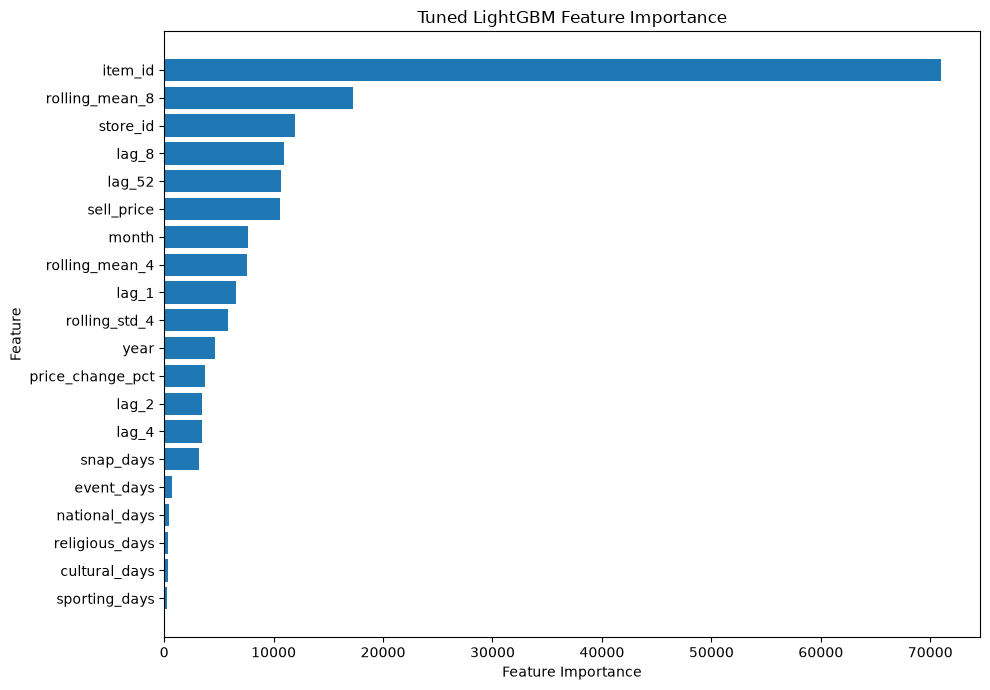

In [227]:
feature_importance = pd.DataFrame({
    "feature": model_features_v3,
    "importance": final_tuned_lgb.feature_importances_
}).sort_values("importance", ascending=False)

display(feature_importance)

plt.figure(figsize=(10, 7))
plt.barh(
    feature_importance["feature"][::-1],
    feature_importance["importance"][::-1]
)
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Tuned LightGBM Feature Importance")
plt.tight_layout()
plt.show()

In [229]:
# Additional lag features
for lag in [3, 12, 26]:
    price_sales_active[f"lag_{lag}"] = (
        price_sales_active
        .groupby(["store_id", "item_id"])["weekly_sales"]
        .shift(lag)
    )

# Additional rolling demand features
price_sales_active["rolling_mean_2"] = (
    price_sales_active
    .groupby(["store_id", "item_id"])["weekly_sales"]
    .transform(lambda x: x.shift(1).rolling(2).mean())
)

price_sales_active["rolling_mean_12"] = (
    price_sales_active
    .groupby(["store_id", "item_id"])["weekly_sales"]
    .transform(lambda x: x.shift(1).rolling(12).mean())
)

# Demand momentum / trend
price_sales_active["momentum_1_4"] = (
    price_sales_active["lag_1"] /
    (price_sales_active["rolling_mean_4"] + 1e-6)
)

price_sales_active["trend_4_8"] = (
    price_sales_active["rolling_mean_4"] /
    (price_sales_active["rolling_mean_8"] + 1e-6)
)

# Historical price level - only past information
price_sales_active["avg_price_item_store"] = (
    price_sales_active
    .groupby(["store_id", "item_id"])["sell_price"]
    .transform(lambda x: x.shift(1).expanding().mean())
)

price_sales_active["price_ratio"] = (
    price_sales_active["sell_price"] /
    (price_sales_active["avg_price_item_store"] + 1e-6)
)

In [230]:
candidate_features = [
    "lag_3",
    "lag_12",
    "lag_26",
    "rolling_mean_2",
    "rolling_mean_12",
    "momentum_1_4",
    "trend_4_8",
    "avg_price_item_store",
    "price_ratio"
]

model_features_candidates = model_features_v3 + candidate_features

print("Current features:", len(model_features_v3))
print("Candidate features:", len(candidate_features))
print("Total features:", len(model_features_candidates))

Current features: 20
Candidate features: 9
Total features: 29


In [231]:
price_sales_active[candidate_features].describe().T

,count,mean,std,min,25%,50%,75%,max
lag_3,6627691.0,9.987926,26.227988,0.000000,1.000000,3.000000,10.000000,3539.000000
lag_12,6353281.0,9.999361,26.400513,0.000000,1.000000,3.000000,10.000000,3539.000000
lag_26,5926607.0,10.075667,26.768131,0.000000,1.000000,3.000000,10.000000,3539.000000
rolling_mean_2,6658181.0,9.990344,25.607240,0.000000,1.000000,3.500000,9.500000,3242.000000
rolling_mean_12,6353281.0,9.979961,24.402401,0.000000,1.416667,3.833333,9.583333,1946.500000
momentum_1_4,6597201.0,0.896160,0.782439,0.000000,0.235294,0.878049,1.257143,4.000000
trend_4_8,6475241.0,0.918165,0.464225,0.000000,0.755555,0.979070,1.142857,2.000000
avg_price_item_store,6688671.0,4.382014,3.389326,0.100000,2.102820,3.370000,5.770000,30.805338
price_ratio,6688671.0,1.007418,0.052957,0.001166,0.999999,1.000000,1.017343,9.999900


In [232]:
model_df_candidates = price_sales_active[
    ["wm_yr_wk", "week_index"]
    + model_features_candidates
    + ["weekly_sales"]
].dropna().copy()

print(model_df_candidates.shape)
print(
    model_df_candidates["week_index"].min(),
    model_df_candidates["week_index"].max()
)

(5136472, 32)
52 277


In [233]:
train_candidates = model_df_candidates[
    model_df_candidates["week_index"] <= 269
].copy()

val_candidates = model_df_candidates[
    model_df_candidates["week_index"].between(270, 273)
].copy()

test_candidates = model_df_candidates[
    model_df_candidates["week_index"].between(274, 277)
].copy()

X_train_candidates = train_candidates[model_features_candidates]
y_train_candidates = train_candidates["weekly_sales"]

X_val_candidates = val_candidates[model_features_candidates]
y_val_candidates = val_candidates["weekly_sales"]

print("Train:", train_candidates.shape)
print("Validation:", val_candidates.shape)
print("Test:", test_candidates.shape)

print(
    "Train weeks:",
    train_candidates["week_index"].min(),
    "-",
    train_candidates["week_index"].max()
)

print(
    "Validation weeks:",
    val_candidates["week_index"].min(),
    "-",
    val_candidates["week_index"].max()
)

print(
    "Test weeks:",
    test_candidates["week_index"].min(),
    "-",
    test_candidates["week_index"].max()
)

Train: (4895700, 32)
Validation: (120242, 32)
Test: (120530, 32)
Train weeks: 52 - 269
Validation weeks: 270 - 273
Test weeks: 274 - 277


In [234]:
import lightgbm as lgb
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

lgb_candidates = LGBMRegressor(
    objective="regression",
    n_estimators=1500,
    learning_rate=0.03,
    num_leaves=63,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

lgb_candidates.fit(
    X_train_candidates,
    y_train_candidates,
    eval_set=[(X_val_candidates, y_val_candidates)],
    eval_metric="rmse",
    categorical_feature=["store_id", "item_id"],
    callbacks=[
        lgb.early_stopping(stopping_rounds=50),
        lgb.log_evaluation(period=100)
    ]
)

pred_candidates = lgb_candidates.predict(
    X_val_candidates,
    num_iteration=lgb_candidates.best_iteration_
)

candidate_mae = mean_absolute_error(
    y_val_candidates,
    pred_candidates
)

candidate_rmse = np.sqrt(
    mean_squared_error(y_val_candidates, pred_candidates)
)

print(f"Candidate model MAE:  {candidate_mae:.4f}")
print(f"Candidate model RMSE: {candidate_rmse:.4f}")
print(f"Best iteration:       {lgb_candidates.best_iteration_}")

/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[100]	valid_0's rmse: 7.21839	valid_0's l2: 52.1052
[200]	valid_0's rmse: 6.98429	valid_0's l2: 48.7803
[300]	valid_0's rmse: 6.91004	valid_0's l2: 47.7486
[400]	valid_0's rmse: 6.88849	valid_0's l2: 47.4513
[500]	valid_0's rmse: 6.87552	valid_0's l2: 47.2728
[600]	valid_0's rmse: 6.86373	valid_0's l2: 47.1107
[700]	valid_0's rmse: 6.85778	valid_0's l2: 47.0291
[800]	valid_0's rmse: 6.85271	valid_0's l2: 46.9597
[900]	valid_0's rmse: 6.84777	valid_0's l2: 46.892
Early stopping, best iteration is:
[871]	valid_0's rmse: 6.84588	valid_0's l2: 46.8661
Candidate model MAE:  3.2174
Candidate model RMSE: 6.8459
Best iteration:       871


In [235]:
from sklearn.inspection import permutation_importance
import pandas as pd

# Validation setinden sabit bir örnek
sample_size = min(30000, len(X_val_candidates))

X_val_perm = X_val_candidates.sample(
    n=sample_size,
    random_state=42
)

y_val_perm = y_val_candidates.loc[X_val_perm.index]

perm_result = permutation_importance(
    lgb_candidates,
    X_val_perm,
    y_val_perm,
    scoring="neg_mean_absolute_error",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

perm_importance = pd.DataFrame({
    "feature": X_val_perm.columns,
    "importance": perm_result.importances_mean,
    "std": perm_result.importances_std
}).sort_values(
    "importance",
    ascending=False
)

display(perm_importance)


,feature,importance,std
2,lag_1,2.828956,0.022177
6,rolling_mean_4,1.184381,0.003202
23,rolling_mean_2,0.868322,0.006734
7,rolling_mean_8,0.246343,0.006856
1,item_id,0.159478,0.002182
3,lag_2,0.114050,0.001060
24,rolling_mean_12,0.113537,0.004510
18,snap_days,0.078547,0.008451
19,lag_52,0.061613,0.002312
25,momentum_1_4,0.055857,0.003926


In [236]:
drop_features = [
    "month",
    "year",
    "sporting_days",
    "event_days",
    "religious_days",
    "national_days",
    "cultural_days"
]

selected_features = [
    f for f in model_features_candidates
    if f not in drop_features
]

print("Before selection:", len(model_features_candidates))
print("After selection:", len(selected_features))
print("\nSelected features:")
print(selected_features)

Before selection: 29
After selection: 22

Selected features:
['store_id', 'item_id', 'lag_1', 'lag_2', 'lag_4', 'lag_8', 'rolling_mean_4', 'rolling_mean_8', 'rolling_std_4', 'sell_price', 'price_change_pct', 'snap_days', 'lag_52', 'lag_3', 'lag_12', 'lag_26', 'rolling_mean_2', 'rolling_mean_12', 'momentum_1_4', 'trend_4_8', 'avg_price_item_store', 'price_ratio']


In [237]:
X_train_selected = train_candidates[selected_features]
X_val_selected = val_candidates[selected_features]

lgb_selected = LGBMRegressor(
    objective="regression",
    n_estimators=1500,
    learning_rate=0.03,
    num_leaves=63,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

lgb_selected.fit(
    X_train_selected,
    y_train_candidates,
    eval_set=[(X_val_selected, y_val_candidates)],
    eval_metric="rmse",
    categorical_feature=["store_id", "item_id"],
    callbacks=[
        lgb.early_stopping(stopping_rounds=50),
        lgb.log_evaluation(period=100)
    ]
)

pred_selected = lgb_selected.predict(
    X_val_selected,
    num_iteration=lgb_selected.best_iteration_
)

selected_mae = mean_absolute_error(
    y_val_candidates,
    pred_selected
)

selected_rmse = np.sqrt(
    mean_squared_error(y_val_candidates, pred_selected)
)

print(f"Selected model MAE:  {selected_mae:.4f}")
print(f"Selected model RMSE: {selected_rmse:.4f}")
print(f"Best iteration:      {lgb_selected.best_iteration_}")

/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[100]	valid_0's rmse: 7.1883	valid_0's l2: 51.6716
[200]	valid_0's rmse: 6.9381	valid_0's l2: 48.1372
[300]	valid_0's rmse: 6.86961	valid_0's l2: 47.1916
[400]	valid_0's rmse: 6.86036	valid_0's l2: 47.0646
Early stopping, best iteration is:
[392]	valid_0's rmse: 6.85833	valid_0's l2: 47.0367
Selected model MAE:  3.2158
Selected model RMSE: 6.8583
Best iteration:      392


In [238]:
# Tuning subset - same time window as previous Optuna experiment
tune_selected = train_candidates[
    train_candidates["week_index"] >= 170
].copy()

X_tune_selected = tune_selected[selected_features]
y_tune_selected = tune_selected["weekly_sales"]

print(X_tune_selected.shape)
print(y_tune_selected.shape)

(2732453, 22)
(2732453,)


In [ ]:
import optuna
import lightgbm as lgb
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error

def objective_v4(trial):

    params = {
        "objective": "regression_l1",
        "n_estimators": 1500,

        "learning_rate": trial.suggest_float(
            "learning_rate", 0.015, 0.08, log=True
        ),
        "num_leaves": trial.suggest_int(
            "num_leaves", 31, 127
        ),
        "max_depth": trial.suggest_int(
            "max_depth", 6, 14
        ),
        "min_child_samples": trial.suggest_int(
            "min_child_samples", 20, 150
        ),
        "subsample": trial.suggest_float(
            "subsample", 0.7, 1.0
        ),
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.7, 1.0
        ),
        "reg_alpha": trial.suggest_float(
            "reg_alpha", 1e-3, 2.0, log=True
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda", 1e-3, 2.0, log=True
        ),

        "random_state": 42,
        "n_jobs": -1,
        "verbosity": -1
    }

    model = LGBMRegressor(**params)

    model.fit(
        X_tune_selected,
        y_tune_selected,
        eval_set=[(X_val_selected, y_val_candidates)],
        eval_metric="mae",
        categorical_feature=["store_id", "item_id"],
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=50,
                verbose=False
            )
        ]
    )

    pred = model.predict(
        X_val_selected,
        num_iteration=model.best_iteration_
    )

    return mean_absolute_error(
        y_val_candidates,
        pred
    )


study_v4 = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

study_v4.optimize(
    objective_v4,
    n_trials=15,
    show_progress_bar=True
)

print(f"Best MAE: {study_v4.best_value:.6f}")

print("\nBest parameters:")
for key, value in study_v4.best_params.items():
    print(f"{key}: {value}")

[I 2026-10-31 01:17:17,174] A new study created in memory with name: no-name-bab6c562-3c78-48fa-a887-d7fa1866b481
  0%|          | 0/15 [00:00<?, ?it/s]/home/neverland/code/zehradedebali-cyber/retail-demand-forecasting/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


In [ ]:
!pip install xgboost

In [ ]:
X_train_xgb = X_train_v3.copy()
X_val_xgb = X_val_v3.copy()

for col in ["store_id", "item_id"]:
    categories = X_train_xgb[col].cat.categories

    X_train_xgb[col] = (
        X_train_xgb[col]
        .cat.codes
        .astype("int32")
    )

    X_val_xgb[col] = (
        X_val_xgb[col]
        .cat.set_categories(categories)
        .cat.codes
        .astype("int32")
    )

In [ ]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    objective="reg:absoluteerror",
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=10,
    min_child_weight=20,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train_xgb,
    y_train_v3,
    eval_set=[(X_val_xgb, y_val_v3)],
    verbose=100
)

In [ ]:
xgb_val_pred = xgb_model.predict(X_val_xgb)

xgb_val_mae = mean_absolute_error(
    y_val_v3,
    xgb_val_pred
)

xgb_val_rmse = np.sqrt(
    mean_squared_error(y_val_v3, xgb_val_pred)
)

print(
    f"XGBoost Validation: "
    f"MAE {xgb_val_mae:.4f} | "
    f"RMSE {xgb_val_rmse:.4f}"
)

In [ ]:
X_tune_xgb = tune_train[model_features_v3].copy()
y_tune_xgb = tune_train["weekly_sales"]

X_tune_val_xgb = val_v3[model_features_v3].copy()
y_tune_val_xgb = val_v3["weekly_sales"]

for col in ["store_id", "item_id"]:
    X_tune_xgb[col] = X_tune_xgb[col].astype("category")
    X_tune_val_xgb[col] = X_tune_val_xgb[col].astype("category")

    categories = X_tune_xgb[col].cat.categories

    X_tune_xgb[col] = X_tune_xgb[col].cat.codes.astype("int32")

    X_tune_val_xgb[col] = (
        X_tune_val_xgb[col]
        .cat.set_categories(categories)
        .cat.codes
        .astype("int32")
    )

In [ ]:
def objective_xgb(trial):

    params = {
        "objective": "reg:absoluteerror",
        "n_estimators": 1500,

        "learning_rate": trial.suggest_float(
            "learning_rate", 0.015, 0.08, log=True
        ),

        "max_depth": trial.suggest_int(
            "max_depth", 6, 14
        ),

        "min_child_weight": trial.suggest_int(
            "min_child_weight", 5, 100
        ),

        "subsample": trial.suggest_float(
            "subsample", 0.7, 1.0
        ),

        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.7, 1.0
        ),

        "reg_alpha": trial.suggest_float(
            "reg_alpha", 1e-3, 2.0, log=True
        ),

        "reg_lambda": trial.suggest_float(
            "reg_lambda", 1e-3, 5.0, log=True
        ),

        "tree_method": "hist",
        "random_state": 42,
        "n_jobs": -1
    }

    model = XGBRegressor(**params)

    model.fit(
        X_tune_xgb,
        y_tune_xgb,
        eval_set=[(X_tune_val_xgb, y_tune_val_xgb)],
        verbose=False
    )

    pred = model.predict(X_tune_val_xgb)

    return mean_absolute_error(
        y_tune_val_xgb,
        pred
    )

In [ ]:
def objective_xgb(trial):

    params = {
        "objective": "reg:absoluteerror",
        "n_estimators": 1500,

        "learning_rate": trial.suggest_float(
            "learning_rate", 0.015, 0.08, log=True
        ),

        "max_depth": trial.suggest_int(
            "max_depth", 6, 14
        ),

        "min_child_weight": trial.suggest_int(
            "min_child_weight", 5, 100
        ),

        "subsample": trial.suggest_float(
            "subsample", 0.7, 1.0
        ),

        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.7, 1.0
        ),

        "reg_alpha": trial.suggest_float(
            "reg_alpha", 1e-3, 2.0, log=True
        ),

        "reg_lambda": trial.suggest_float(
            "reg_lambda", 1e-3, 5.0, log=True
        ),

        "tree_method": "hist",
        "random_state": 42,
        "n_jobs": -1
    }

    model = XGBRegressor(**params)

    model.fit(
        X_tune_xgb,
        y_tune_xgb,
        eval_set=[(X_tune_val_xgb, y_tune_val_xgb)],
        verbose=False
    )

    pred = model.predict(X_tune_val_xgb)

    return mean_absolute_error(
        y_tune_val_xgb,
        pred
    )

In [ ]:
study_xgb = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

study_xgb.optimize(
    objective_xgb,
    n_trials=15,
    show_progress_bar=True
)

print("Best XGBoost MAE:", study_xgb.best_value)

print("\nBest parameters:")
for key, value in study_xgb.best_params.items():
    print(f"{key}: {value}")

In [ ]:
from catboost import CatBoostRegressor

In [ ]:
get_ipython().system('pip install CatBoost')

In [ ]:
from catboost import CatBoostRegressor

In [ ]:
X_train_cat = train_v3[model_features_v3].copy()
y_train_cat = train_v3["weekly_sales"]

X_val_cat = val_v3[model_features_v3].copy()
y_val_cat = val_v3["weekly_sales"]

for col in ["store_id", "item_id"]:
    X_train_cat[col] = X_train_cat[col].astype(str)
    X_val_cat[col] = X_val_cat[col].astype(str)

In [ ]:
cat_model = CatBoostRegressor(
    loss_function="MAE",
    eval_metric="MAE",
    iterations=1000,
    learning_rate=0.05,
    depth=10,
    l2_leaf_reg=3,
    random_seed=42,
    verbose=100,
    thread_count=-1,
    allow_writing_files=False
)

cat_model.fit(
    X_train_cat,
    y_train_cat,
    cat_features=["store_id", "item_id"],
    eval_set=(X_val_cat, y_val_cat),
    early_stopping_rounds=75,
    verbose=100
)